# Session 14: Training a Dense LM and Growing It into a Mixture-of-Experts

**Assignment (lesson §21).** *"Train a Linear model and convert that into an MoE! Your call on model size and data
trained on, but must show they continue to train and reduce loss!"*

"Linear" here means a **dense** model: every token passes through one full feed-forward network (FFN) in every layer.
The plan:

1. **Train a dense model.** A 20.8M-parameter Llama-style decoder trained on the first 40M tokens of TinyStories (§4).
2. **Convert it into an MoE** by *upcycling* (lesson §15). Each layer's 1,024-wide FFN becomes **32 experts of width
   256**, built from slices of the dense FFN with half of each expert's neurons redrawn (*drop-upcycling*). A new
   router picks **4 experts per token**. A token therefore still uses 4 × 256 = 1,024 FFN neurons, the same compute as
   the dense model, while the model now stores 5× as many parameters (§6).
3. **Keep training** the MoE on the next 20M tokens and show the loss keeps falling. It is compared with the same dense
   model trained on the same 20M tokens, and with the same MoE trained from scratch on all 60M tokens (§7).

Extra experiments that explain *why* the results come out as they do:

| § | experiment | question |
|---|---|---|
| 8 | five ways to build the experts (copy, partition, drop r = 0.25 / 0.5 / 1.0) | which start keeps the most knowledge, and which trains best? |
| 9 | three balancing methods (none, auxiliary loss, bias) | does routing collapse without balancing, and what does each fix cost? |
| 10 | what the experts learn | do experts specialise by kind of token, as the lesson's §9 says? |
| 11 | capacity and token dropping | how many tokens would a capacity limit drop, and what does that cost? |
| 12 | cost | parameters, speed and memory of dense vs MoE |

```text
training tokens:   0 ─────────────────────── 40M ──────────── 60M
                   dense, phase A (Task 1)    │ dense continued        (control: same model, no MoE)
                                              │ upcycled MoE           (Task 2 + 3, the main run)
                   MoE from scratch ──────────┴───────────────── 60M   (control: no dense start)
sweeps (§8, §9):                              40M ── 45M
```

**Words used throughout.** An **expert** is one small SwiGLU FFN. The **router** is a $D \times E$ matrix that gives
each token one score per expert. **Top-k** keeps the $k$ best. **Total parameters** are everything stored, and
**active parameters** are what one token uses. The **load** of an expert is how many tokens it received. **MaxVio** is
(busiest load − mean load) / mean load, which is 0 when perfectly even. **Upcycling** builds the MoE from a trained
dense model instead of from random weights. The file `doubts/s14_moe_terms.md` explains each term with tiny examples,
and the sections below repeat what is needed.

**Runtime.** About 2 hours on one Colab **L4**; the four main runs alone took 88 minutes. The from-scratch control
(55 min) can be switched off with `RUN_SCRATCH = False` in §7.

## 0. Setup

`PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True` lets PyTorch's memory allocator grow a segment instead of leaving
holes. The MoE produces tensors of a different size at every step (each expert gets a different number of tokens), so
this avoids fragmentation. TF32 lets fp32 matrix products use the tensor cores. Training itself runs in bf16 autocast.

In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # must be set before torch touches the GPU
!pip -q install tiktoken

import gc, json, math, time, string, importlib
from dataclasses import replace
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "this notebook needs a GPU runtime (L4 recommended)"
props = torch.cuda.get_device_properties(0)
print(f"PyTorch {torch.__version__}, CUDA {torch.version.cuda}")
print(f"GPU: {props.name}, compute capability {props.major}.{props.minor}, memory {props.total_memory / 2**30:.2f} GiB")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

os.makedirs("plots", exist_ok=True)
RESULTS = {}                                     # every run's summary; written to results.json after each run

def savefig(name):
    "Save the current figure to plots/<name>.png and show it inline."
    plt.savefig(f"plots/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def save_results():
    "Write RESULTS to results.json (per-step expert loads left out), so a crash late in the notebook loses nothing."
    clean = {k: ({kk: vv for kk, vv in v.items() if kk != "loads"} if isinstance(v, dict) else v)
             for k, v in RESULTS.items()}
    with open("results.json", "w") as f:
        json.dump(clean, f, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))

def smooth(v, w=25):
    "Trailing moving average with window w (shorter at the start). Example: smooth([1, 3, 5], 2) -> [1., 2., 4.]"
    v = np.asarray(v, dtype=float)
    c = np.cumsum(np.insert(v, 0, 0.0))                                 # c[i] = sum of the first i values
    i = np.arange(1, len(v) + 1)
    lo = np.maximum(i - w, 0)
    return (c[i] - c[lo]) / (i - lo)

PyTorch 2.11.0+cu130, CUDA 13.0
GPU: NVIDIA L4, compute capability 8.9, memory 22.03 GiB


### The code file

`moellm.py` holds everything reusable:

* the model: RMSNorm, RoPE attention, SwiGLU, tied embedding; the FFN is dense or an `MoE` layer;
* the MoE layer: a sigmoid router in fp32, top-k with a selection bias, sort-based dropless dispatch, and the two
  auxiliary losses;
* `upcycle()`, which turns a dense model into an MoE by copy, partition or drop-upcycling;
* `train()`, the training loop: warm-up–stable–decay schedule, bias updates, per-step expert loads;
* diagnostics: `maxvio`, `dead_experts`, `routing_probe`, `evaluate_capacity`, `clone_similarity`.

Colab cannot see local files, so the cell writes the file onto the runtime.

In [2]:
%%writefile moellm.py
"""Dense and Mixture-of-Experts Llama-style LMs, dense -> MoE upcycling, training loop and routing diagnostics.

Architecture (pre-norm Llama block, the same family as Assignments 10-13):

    token ids (B, T)
      -> Embedding (tied with the LM head)                                  x (B, T, D), fp32 residual stream
      -> L blocks:   p = p + Attn(RMSNorm(p))
                     p = p + FFN(RMSNorm(p))
                         FFN = SwiGLU of width F                             (dense model)
                             = MoE: router + E SwiGLU experts of width Fe     (MoE model, k experts per token)
      -> RMSNorm -> logits = h @ Emb^T  (B, T, V) -> cross-entropy

MoE layer, for the N = B*T tokens of a batch (lesson sections 3, 7, 11, 13):

    logits  = x @ Wr^T                          (N, E)   computed in fp32 (router stability, lesson section 7)
    scores  = sigmoid(logits)                   (N, E)   each in (0, 1), no competition (DeepSeek-V3 style;
                                                         score_fn="softmax" gives the Qwen3 / Switch style)
    chosen  = top-k of (scores + bias)          (N, k)   the bias steers only the choice (aux-loss-free balancing)
    weights = scores[chosen] / sum * scale      (N, k)   scale = routed scaling factor (= k here, see upcycle())
    y       = sum_j weights_j * Expert_{chosen_j}(x)

Dispatch is sort-based and dropless: the A = N*k (token, expert) assignments are sorted by expert id, each expert
runs once on its contiguous block of rows (any length, so no token is dropped), and the weighted outputs are
scatter-added back to their tokens. capacity_factor > 0 switches on token dropping (used for analysis only).

Notation in docstrings and shape comments:
    B sequences per batch   T tokens per sequence   D d_model    H heads      hd = D / H
    F dense FFN width       E experts               Fe expert width          k experts per token
    V vocabulary size       L layers                N = B * T tokens         A = N * k assignments
"""
import gc
import math
import time
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class Config:
    vocab_size: int = 8192
    n_layer: int = 10              # L
    n_head: int = 6                # H   (hd = 384 / 6 = 64)
    d_model: int = 384             # D
    d_ff: int = 1024               # F, width of the dense SwiGLU
    max_seq: int = 512             # T the RoPE tables are built for
    rope_base: float = 10000.0
    # ---- MoE (n_expert = 0 means the dense model)
    n_expert: int = 0              # E
    expert_ff: int = 256           # Fe
    top_k: int = 4                 # k
    route_scale: float = 4.0       # routed scaling factor: the k weights of a token add up to this
    score_fn: str = "sigmoid"      # "sigmoid" (DeepSeek-V3, Kimi K2, GLM-4.5) or "softmax" (Qwen3, Switch)
    router_std_mult: float = 0.1   # router init std = mult / sqrt(D)  (Switch Transformer: 0.1 x the usual scale)
    bias_gamma: float = 1e-3       # aux-loss-free bias update speed per step; 0 = no bias balancing
    aux_alpha: float = 0.0         # Switch batch-level auxiliary loss coefficient
    seq_aux_alpha: float = 1e-4    # sequence-level auxiliary loss coefficient (DeepSeek-V3 style safety net)
    capacity_factor: float = 0.0   # 0 = dropless; > 0 drops assignments beyond capacity (analysis only)

    @property
    def is_moe(self):
        return self.n_expert > 0

    def label(self):
        """Short run name. Example: Config().label() -> 'dense F=1024';
        Config(n_expert=32).label() -> 'MoE 32x256 top-4, bias 0.001 + seq-aux 0.0001'"""
        if not self.is_moe:
            return f"dense F={self.d_ff}"
        bal = []
        if self.bias_gamma > 0:
            bal.append(f"bias {self.bias_gamma:g}")
        if self.aux_alpha > 0:
            bal.append(f"aux {self.aux_alpha:g}")
        if self.seq_aux_alpha > 0:
            bal.append(f"seq-aux {self.seq_aux_alpha:g}")
        return f"MoE {self.n_expert}x{self.expert_ff} top-{self.top_k}, " + (" + ".join(bal) or "no balancing")


# ----------------------------------------------------------------------------------------- layers
class RMSNorm(nn.Module):
    """y = x / sqrt(mean(x^2) + eps) * w.

    Example: RMSNorm(4)(torch.tensor([[3., -3., 3., -3.]])) -> tensor([[1., -1., 1., -1.]])
    """

    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):                                                   # (..., D) -> (..., D)
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight


def rope_tables(hd, T, base):
    """cos, sin tables for rotary position embedding, each (T, hd/2).

    Example: rope_tables(4, 2, 10000.)[0] -> tensor([[1., 1.], [0.5403, 0.9999]])   (cos of angle t * base^(-2i/hd))
    """
    inv = base ** (-torch.arange(0, hd, 2).float() / hd)                      # (hd/2,)
    ang = torch.arange(T).float()[:, None] * inv[None]                        # (T, hd/2)
    return ang.cos(), ang.sin()


def apply_rope(x, cos, sin):
    """Rotate each (even, odd) feature pair of x (B, H, T, hd) by its position's angle. Norm-preserving.

    Example: one head, hd=2, position 1, angle 1 rad: (1, 0) -> (cos 1, sin 1) = (0.5403, 0.8415)
    """
    x1, x2 = x[..., 0::2], x[..., 1::2]                                       # (B, H, T, hd/2) each
    out = torch.stack((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1)     # (B, H, T, hd/2, 2)
    return out.flatten(-2)                                                    # (B, H, T, hd)


class Attention(nn.Module):
    """Causal multi-head self-attention with RoPE, no biases. (B, T, D) -> (B, T, D).

    Example: Attention(Config())(torch.randn(2, 16, 384)).shape -> torch.Size([2, 16, 384])
    """

    def __init__(self, cfg):
        super().__init__()
        self.H, self.hd = cfg.n_head, cfg.d_model // cfg.n_head
        self.qkv = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)
        self.proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        cos, sin = rope_tables(self.hd, cfg.max_seq, cfg.rope_base)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.H, self.hd).permute(2, 0, 3, 1, 4)   # 3 x (B, H, T, hd)
        cos, sin = self.cos[:T].to(q.dtype), self.sin[:T].to(q.dtype)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)                     # (B, H, T, hd)
        return self.proj(y.transpose(1, 2).reshape(B, T, D))                            # (B, T, D)


class SwiGLU(nn.Module):
    """Dense gated feed-forward: w2( silu(w1 x) * w3 x ), hidden width F. (B, T, D) -> (B, T, D).

    It is a sum over its F hidden neurons, which is what makes partition upcycling exact:
        FFN(x) = sum_j  w2[:, j] * silu(w1[j] . x) * (w3[j] . x)

    Example: SwiGLU(Config())(torch.randn(2, 16, 384)).shape -> torch.Size([2, 16, 384])
    """

    def __init__(self, cfg):
        super().__init__()
        self.w1 = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)    # gate  (F, D)
        self.w3 = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)    # up    (F, D)
        self.w2 = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)    # down  (D, F)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


# ------------------------------------------------------------------------------------------- MoE
def switch_aux(f, P, alpha):
    """Switch Transformer load-balancing loss  alpha * E * sum_i f_i P_i  over the last axis.

    f: share of assignments sent to each expert (no gradient), P: mean router probability per expert.
    Example (E = 4): even  f = P = [.25]*4      -> alpha * 4 * 0.25 = alpha        (0.01 for alpha = 0.01)
                     collapsed f = P = [1,0,0,0] -> alpha * 4 * 1    = 4 * alpha   (0.04)
    """
    E = f.shape[-1]
    return alpha * E * (f * P).sum(-1)


def dispatch_plan(flat_e, E):
    """Group the A assignments by expert (sort-based dispatch).

    flat_e (A,): expert id of assignment a = token * k + j.
    Returns order (A,): assignment indices sorted by expert, token order kept inside each expert (stable sort);
            counts (E,): assignments per expert;  pos (A,): arrival rank of each sorted assignment in its expert.
    Example: flat_e = [2, 0, 2, 1, 0, 2], E = 3 -> order = [1, 4, 3, 0, 2, 5], counts = [2, 1, 3],
             pos = [0, 1, 0, 0, 1, 2]   (with capacity 2, the assignment with pos 2, token 5, would be dropped)
    """
    order = torch.argsort(flat_e, stable=True)                                # (A,)
    counts = torch.bincount(flat_e, minlength=E)                              # (E,)
    starts = torch.cumsum(counts, 0) - counts                                 # (E,) first sorted row of each expert
    pos = torch.arange(flat_e.numel(), device=flat_e.device) - starts[flat_e[order]]   # (A,)
    return order, counts, pos


class MoE(nn.Module):
    """Router + E SwiGLU experts of width Fe, top-k, dropless sort-based dispatch. (B, T, D) -> (B, T, D).

    Expert e:  E_e(x) = w2[e] ( silu(w1[e] x) * w3[e] x ),   w1[e], w3[e]: (Fe, D),  w2[e]: (D, Fe).
    After every forward pass the layer keeps:  last_counts (E,) assignments per expert in that batch,
    aux (scalar or None) its auxiliary loss, last_topi (N, k) the chosen experts if record is True,
    last_dropped the share of assignments dropped by a capacity limit (0 when dropless).

    Example: MoE(Config(n_expert=32))(torch.randn(2, 16, 384)).shape -> torch.Size([2, 16, 384]),
             and .last_counts.sum() -> 2 * 16 * 4 = 128
    """

    def __init__(self, cfg):
        super().__init__()
        E, Fe, D = cfg.n_expert, cfg.expert_ff, cfg.d_model
        self.cfg, self.E, self.k = cfg, E, cfg.top_k
        self.router = nn.Parameter(torch.empty(E, D))                         # Wr (E, D), fp32
        self.w1 = nn.Parameter(torch.empty(E, Fe, D))                         # gate
        self.w3 = nn.Parameter(torch.empty(E, Fe, D))                         # up
        self.w2 = nn.Parameter(torch.empty(E, D, Fe))                         # down
        self.register_buffer("bias", torch.zeros(E))                          # selection bias, not trained by gradient
        self.aux, self.last_counts, self.last_topi, self.last_dropped, self.record = None, None, None, 0.0, False

    def route(self, xf):
        """xf (N, D) -> probs (N, E), chosen experts topi (N, k), their weights topw (N, k), all fp32.

        probs = scores normalised to sum to 1 over the experts (the P_i of the auxiliary losses; for softmax this
        is the softmax itself). Example, sigmoid, 8 experts, k = 2, logits [2.0, .5, 1.2, -.3, .9, 1.8, -1., .1]:
        scores [.881, .622, .769, .426, .711, .858, .269, .525] -> topi [0, 5], topw [.507, .493] * route_scale
        """
        with torch.autocast(device_type=xf.device.type, enabled=False):
            logits = F.linear(xf.float(), self.router.float())                # (N, E) in fp32
        if self.cfg.score_fn == "softmax":
            scores = logits.softmax(-1)                                       # (N, E), sum to 1
        else:
            scores = torch.sigmoid(logits)                                    # (N, E), each in (0, 1)
        topi = (scores + self.bias).topk(self.k, dim=-1).indices              # (N, k) choice uses the bias
        topw = scores.gather(-1, topi)                                        # (N, k) weights do not
        topw = topw / topw.sum(-1, keepdim=True) * self.cfg.route_scale
        probs = scores / scores.sum(-1, keepdim=True)                         # (N, E)
        return probs, topi, topw

    def forward(self, x):
        B, T, D = x.shape
        N, k, E = B * T, self.k, self.E
        xf = x.reshape(N, D)                                                  # (N, D)
        probs, topi, topw = self.route(xf)
        flat_e = topi.reshape(-1)                                             # (A,)
        order, counts, pos = dispatch_plan(flat_e, E)
        tok = order // k                                                      # (A,) token of each sorted assignment
        w = topw.reshape(-1)[order]                                           # (A,) its router weight
        if self.cfg.capacity_factor > 0:                                      # token dropping, first come first served
            cap = math.ceil(N * k / E * self.cfg.capacity_factor)
            keep = pos < cap
            w = w * keep
            self.last_dropped = 1.0 - keep.float().mean().item()
        else:
            self.last_dropped = 0.0
        xs = xf[tok]                                                          # (A, D) rows grouped by expert
        w1s, w3s, w2s = self.w1.unbind(0), self.w3.unbind(0), self.w2.unbind(0)   # unbind: one cheap backward op
        outs, s = [], 0
        for e, c in enumerate(counts.tolist()):                               # one matmul chain per expert
            if c:
                h = xs[s:s + c]                                               # (c, D)
                outs.append(F.linear(F.silu(F.linear(h, w1s[e])) * F.linear(h, w3s[e]), w2s[e]))   # (c, D)
                s += c
        out = torch.cat(outs)                                                 # (A, D)
        y = torch.zeros(N, D, device=x.device, dtype=torch.float32)
        y.index_add_(0, tok, out.float() * w[:, None])                        # combine: k weighted outputs per token
        self.last_counts = counts.detach()
        if self.record:
            self.last_topi = topi.detach()
        cfg = self.cfg
        if self.training and (cfg.aux_alpha > 0 or cfg.seq_aux_alpha > 0):
            aux = probs.new_zeros(())
            if cfg.aux_alpha > 0:                                             # over the whole batch
                aux = aux + switch_aux(counts.float() / (N * k), probs.mean(0), cfg.aux_alpha)
            if cfg.seq_aux_alpha > 0:                                         # per sequence, then averaged
                ones = torch.ones(B, T * k, device=x.device)
                f_seq = torch.zeros(B, E, device=x.device).scatter_add_(1, topi.view(B, T * k), ones) / (T * k)
                aux = aux + switch_aux(f_seq, probs.view(B, T, E).mean(1), cfg.seq_aux_alpha).mean()
            self.aux = aux
        else:
            self.aux = None
        return y.to(x.dtype).view(B, T, D)

    @torch.no_grad()
    def update_bias(self):
        """Aux-loss-free balancing step: b_i += gamma * sign(mean load - load_i), from the last batch's counts.

        Example: counts [5, 1, 1, 1], gamma 0.001 -> bias change [-0.001, +0.001, +0.001, +0.001]
        """
        if self.cfg.bias_gamma > 0 and self.last_counts is not None:
            c = self.last_counts.float()
            self.bias += self.cfg.bias_gamma * torch.sign(c.mean() - c)


class Block(nn.Module):
    """Pre-norm block: p + Attn(LN1 p), then + FFN(LN2 p), with FFN = SwiGLU (dense) or MoE."""

    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.attn = RMSNorm(cfg.d_model), Attention(cfg)
        self.ln2 = RMSNorm(cfg.d_model)
        self.ffn = MoE(cfg) if cfg.is_moe else SwiGLU(cfg)

    def forward(self, p):                                                     # (B, T, D) -> (B, T, D)
        p = p + self.attn(self.ln1(p))
        return p + self.ffn(self.ln2(p))


class LM(nn.Module):
    """Decoder-only LM with tied embedding; dense or MoE feed-forward blocks.

    forward(idx (B, T), targets (B, T) or None) -> mean cross-entropy (scalar) or logits (B, T, V) in fp32.
    After a training forward, aux_loss() returns the sum of the MoE layers' auxiliary losses (or None).

    Example: m = LM(Config()); m(torch.randint(0, 8192, (2, 16)), torch.randint(0, 8192, (2, 16)))
             -> tensor(9.01...) at initialisation  (about ln 8192 = 9.011)
    """

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList(Block(cfg) for _ in range(cfg.n_layer))
        self.norm = RMSNorm(cfg.d_model)
        self._init()

    def _init(self):
        """Embedding std 0.02; input matrices std 1/sqrt(fan_in); residual-output matrices (attn.proj, w2) further
        / sqrt(2L). MoE: w2 uses fan_in k*Fe (the k chosen experts together play the role of one F-wide FFN),
        router std router_std_mult / sqrt(D), so the first router scores are almost equal (sigmoid ~ 0.5)."""
        c, L = self.cfg, self.cfg.n_layer
        nn.init.normal_(self.emb.weight, std=0.02)
        for b in self.blocks:
            nn.init.normal_(b.attn.qkv.weight, std=c.d_model ** -0.5)
            nn.init.normal_(b.attn.proj.weight, std=c.d_model ** -0.5 / math.sqrt(2 * L))
            f = b.ffn
            if isinstance(f, MoE):
                nn.init.normal_(f.w1, std=c.d_model ** -0.5)
                nn.init.normal_(f.w3, std=c.d_model ** -0.5)
                nn.init.normal_(f.w2, std=(c.top_k * c.expert_ff) ** -0.5 / math.sqrt(2 * L))
                nn.init.normal_(f.router, std=c.router_std_mult * c.d_model ** -0.5)
            else:
                nn.init.normal_(f.w1.weight, std=c.d_model ** -0.5)
                nn.init.normal_(f.w3.weight, std=c.d_model ** -0.5)
                nn.init.normal_(f.w2.weight, std=c.d_ff ** -0.5 / math.sqrt(2 * L))

    def moe_layers(self):
        return [b.ffn for b in self.blocks if isinstance(b.ffn, MoE)]

    def aux_loss(self):
        terms = [m.aux for m in self.moe_layers() if m.aux is not None]
        return sum(terms) if terms else None

    def forward(self, idx, targets=None):
        x = self.emb(idx)                                                     # (B, T, D)
        for b in self.blocks:
            x = b(x)
        logits = F.linear(self.norm(x), self.emb.weight)                      # (B, T, V), tied head
        if targets is None:
            return logits.float()
        return F.cross_entropy(logits.float().view(-1, logits.shape[-1]), targets.reshape(-1))


def count_params(model):
    """Parameter count by group, with the active count (what one token uses).

    Example: count_params(LM(Config())) -> {'embedding (tied head)': 3145728, 'attention': 5898240,
             'norms': 8064, 'FFN / experts': 11796480, 'router': 0, 'total': 20848512, 'active': 20848512}
    """
    c = model.cfg
    emb = model.emb.weight.numel()
    attn = sum(p.numel() for b in model.blocks for p in b.attn.parameters())
    norms = sum(p.numel() for n, p in model.named_parameters() if ".ln" in n or n == "norm.weight")
    if c.is_moe:
        ffn = sum(m.w1.numel() + m.w3.numel() + m.w2.numel() for m in model.moe_layers())
        router = sum(m.router.numel() for m in model.moe_layers())
        active_ffn = ffn * c.top_k // c.n_expert
    else:
        ffn = sum(p.numel() for b in model.blocks for p in b.ffn.parameters())
        router, active_ffn = 0, ffn
    total = emb + attn + norms + ffn + router
    return {"embedding (tied head)": emb, "attention": attn, "norms": norms, "FFN / experts": ffn,
            "router": router, "total": total, "active": total - ffn + active_ffn}


# ------------------------------------------------------------------------------------- upcycling
@torch.no_grad()
def upcycle(dense, moe_cfg, method="partition", r=0.0, seed=0):
    """Build an MoE LM from a trained dense LM (lesson section 15). Everything outside the FFNs (embedding,
    attention, norms) is copied; each router gets a fresh, small random init and a zero bias.

    method "copy":      every expert is a full copy of the dense FFN (needs expert_ff == d_ff).
    method "partition": the F neurons are cut into S = F / Fe slices; expert e takes slice e % S (its "family"),
                        so experts e, e+S, e+2S, ... start as clones of the same slice.
    r > 0 ("drop-upcycling"): in every expert a random fraction r of its Fe neurons is redrawn (its w1, w3 rows
    and w2 column) from N(mean, std) of the corresponding dense matrix; each expert redraws a different subset.

    Returns (moe_model, family), family (E,) = the dense slice each expert came from.
    Example: dense F = 1024, moe_cfg E = 32, Fe = 256, "partition" -> family = [0, 1, 2, 3, 0, 1, 2, 3, ...]
             (4 families of 8 clones);  "copy" with E = 8, Fe = 1024 -> family = [0] * 8
    """
    dc, E, Fe = dense.cfg, moe_cfg.n_expert, moe_cfg.expert_ff
    assert (dc.d_model, dc.n_layer, dc.n_head, dc.vocab_size) == \
           (moe_cfg.d_model, moe_cfg.n_layer, moe_cfg.n_head, moe_cfg.vocab_size), "shapes must match"
    if method == "copy":
        assert Fe == dc.d_ff, "copy needs expert_ff == d_ff"
        S = 1
    else:
        assert method == "partition" and dc.d_ff % Fe == 0, (method, dc.d_ff, Fe)
        S = dc.d_ff // Fe
    dev = next(dense.parameters()).device
    torch.manual_seed(seed)                                                   # router init
    moe = LM(moe_cfg).to(dev)
    sd = {n: v for n, v in dense.state_dict().items() if ".ffn." not in n}
    missing, unexpected = moe.load_state_dict(sd, strict=False)
    assert not unexpected and all(".ffn." in n for n in missing), (missing, unexpected)
    family = torch.arange(E) % S
    g = torch.Generator().manual_seed(seed)
    n_new = int(round(r * Fe))
    for bd, bm in zip(dense.blocks, moe.blocks):
        W1, W3, W2 = bd.ffn.w1.weight, bd.ffn.w3.weight, bd.ffn.w2.weight    # (F, D), (F, D), (D, F)
        m = bm.ffn
        for e in range(E):
            sl = slice(int(family[e]) * Fe, (int(family[e]) + 1) * Fe)
            m.w1[e].copy_(W1[sl]); m.w3[e].copy_(W3[sl]); m.w2[e].copy_(W2[:, sl])
            if n_new:
                idx = torch.randperm(Fe, generator=g)[:n_new].to(dev)        # neurons of this expert to redraw
                D = W1.shape[1]
                m.w1[e][idx] = (torch.randn(n_new, D, generator=g).to(dev) * W1.std() + W1.mean())
                m.w3[e][idx] = (torch.randn(n_new, D, generator=g).to(dev) * W3.std() + W3.mean())
                m.w2[e][:, idx] = (torch.randn(D, n_new, generator=g).to(dev) * W2.std() + W2.mean())
    return moe, family


# ------------------------------------------------------------------------------------ training
def make_optimizer(model, lr):
    """AdamW(0.9, 0.95), weight decay 0.1 on matrices (embedding, experts, router included), none on norm gains."""
    decay = [p for p in model.parameters() if p.dim() >= 2]
    other = [p for p in model.parameters() if p.dim() < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": 0.1}, {"params": other, "weight_decay": 0.0}],
                             lr=lr, betas=(0.9, 0.95), fused=torch.cuda.is_available())


def lr_at(step, total, peak, warmup, decay_frac=0.2, floor=0.1):
    """Warmup-stable-decay (WSD): linear warm-up over `warmup` steps, constant peak, then a linear decay to
    floor * peak over the last decay_frac of the steps. decay_frac = 0: no decay (a "mid-training" checkpoint).

    Example: lr_at(0, 100, 1e-3, 10) -> 1e-4;  lr_at(50, 100, 1e-3, 10) -> 1e-3;  lr_at(99, 100, 1e-3, 10) -> 1e-4;
             lr_at(99, 100, 1e-3, 10, decay_frac=0) -> 1e-3
    """
    if step < warmup:
        return peak * (step + 1) / warmup
    d0 = total - int(round(decay_frac * total))
    if decay_frac <= 0 or step < d0:
        return peak
    return peak * (1 - (1 - floor) * (step - d0 + 1) / (total - d0))


@torch.no_grad()
def evaluate(model, val, n_windows, batch=64):
    """Mean next-token loss over the first n_windows rows of val (W, T+1), bf16 autocast, no auxiliary loss."""
    was = model.training
    model.eval()
    tot, cnt = 0.0, 0
    for i in range(0, n_windows, batch):
        w = val[i:min(i + batch, n_windows)]
        with torch.autocast("cuda", dtype=torch.bfloat16):
            loss = model(w[:, :-1], w[:, 1:])
        tot += loss.item() * w.shape[0]
        cnt += w.shape[0]
    model.train(was)
    return tot / cnt


def train(model, train_tok, val, *, start_token=0, n_tokens, batch=64, seq=512, lr=1.5e-3, warmup_frac=0.02,
          decay_frac=0.2, eval_every=50, eval_windows=1024, final_eval_windows=1024, log_every=50, seed=1337,
          label=None, quiet=False):
    """Train `model` in place on train_tok[start_token : start_token + n_tokens], read in order, once.

    Step s uses tokens [start + s*B*T, start + (s+1)*B*T + 1): inputs = first B*T, targets shifted by one.
    Fresh AdamW, WSD schedule (see lr_at). Loss = LM loss + MoE auxiliary losses; only the LM loss is logged
    as "train loss". After each optimizer step every MoE layer updates its selection bias.
    Speed = tokens per second of pure training-step time (eval excluded), measured after 5 warm-up steps.

    Returns a dict, e.g. {'label': ..., 'steps': 610, 'val_start': 2.4, 'final_val': 1.9, 'tok_per_s': 5e4,
        'peak_gib': 9.1, 'hist': [(step, global_tokens, lm_loss, aux_loss, grad_norm), ...],
        'val_hist': [(step, global_tokens, val_loss), ...], 'loads': array (steps, L, E) or None}
    """
    dev = "cuda"
    label = label or model.cfg.label()
    torch.manual_seed(seed)
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model.train()
    opt = make_optimizer(model, lr)
    moes = model.moe_layers()
    tps = batch * seq
    steps = n_tokens // tps
    warmup = max(1, int(round(warmup_frac * steps)))
    v0 = evaluate(model, val, eval_windows)
    hist, val_hist, loads = [], [(0, start_token, v0)], []
    t_train, n_timed, t_start, diverged = 0.0, 0, time.time(), False
    if not quiet:
        print(f"  [{label}] {steps} steps of {tps:,} tokens, tokens {start_token / 1e6:.0f}M -> "
              f"{(start_token + steps * tps) / 1e6:.0f}M;  val loss before the first step {v0:.4f}")
    for step in range(steps):
        if step == 5:
            torch.cuda.synchronize(); t_train, n_timed = 0.0, 0
        t0 = time.perf_counter()
        a = start_token + step * tps
        buf = train_tok[a: a + tps + 1].long()
        x, y = buf[:-1].view(batch, seq), buf[1:].view(batch, seq)            # (B, T) each
        for gp in opt.param_groups:
            gp["lr"] = lr_at(step, steps, lr, warmup, decay_frac)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            loss = model(x, y)
        aux = model.aux_loss()
        (loss + aux if aux is not None else loss).backward()
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        opt.zero_grad(set_to_none=True)
        if moes:
            loads.append(torch.stack([m.last_counts for m in moes]).cpu().numpy().astype(np.int32))   # (L, E)
            for m in moes:
                m.update_bias()
        lv = loss.item()                                                      # synchronises the GPU
        t_train += time.perf_counter() - t0
        n_timed += 1 if step >= 5 else 0
        g_tok = a + tps
        hist.append((step + 1, g_tok, lv, aux.item() if aux is not None else 0.0, float(gnorm)))
        if not math.isfinite(lv):
            diverged = True
            print(f"  [{label}] loss became {lv} at step {step + 1}: stopping this run")
            break
        last = step == steps - 1
        if (step + 1) % eval_every == 0 and not last:
            val_hist.append((step + 1, g_tok, evaluate(model, val, eval_windows)))
        if not quiet and ((step + 1) % log_every == 0 or step == 0 or last):
            vtxt = f"   val {val_hist[-1][2]:.4f}" if val_hist[-1][0] == step + 1 else ""
            mv = ""
            if moes:
                c = loads[-1].astype(float)
                mv = f"  MaxVio (mean over layers) {((c.max(1) - c.mean(1)) / c.mean(1)).mean():.2f}"
            print(f"  [{label}] step {step + 1:5d}/{steps}  tokens {g_tok / 1e6:6.2f}M  train loss {lv:.4f}  "
                  f"grad norm {float(gnorm):.3f}  lr {opt.param_groups[0]['lr']:.2e}{mv}{vtxt}")
    peak = torch.cuda.max_memory_allocated() / 2**30
    final_val = evaluate(model, val, final_eval_windows) if not diverged else float("nan")
    val_hist.append((len(hist), start_token + len(hist) * tps, final_val))
    tail = [h[2] for h in hist[-20:]]
    res = {"label": label, "batch": batch, "seq": seq, "tokens_per_step": tps, "steps": len(hist),
           "start_token": start_token, "lr": lr, "warmup_steps": warmup, "decay_frac": decay_frac,
           "val_start": v0, "final_train": sum(tail) / len(tail), "final_val": final_val,
           "tok_per_s": n_timed * tps / max(t_train, 1e-9), "train_time_s": t_train,
           "wall_s": time.time() - t_start, "peak_gib": peak, "diverged": diverged,
           "hist": hist, "val_hist": val_hist, "loads": np.stack(loads) if loads else None}
    del opt
    gc.collect(); torch.cuda.empty_cache()
    return res


# ---------------------------------------------------------------------------------- diagnostics
def maxvio(counts):
    """(max load - mean load) / mean load over the last axis.

    Example: maxvio([2, 2, 2, 2]) -> 0.0;  maxvio([5, 1, 1, 1]) -> 1.5;  maxvio([8, 0, 0, 0]) -> 3.0
    """
    c = np.asarray(counts, dtype=float)
    m = c.mean(-1)
    return (c.max(-1) - m) / m


def dead_experts(counts, frac=0.01):
    """Number of experts whose load is below frac * the even load, over the last axis.

    Example: dead_experts([500, 500, 3, 997]) -> 1   (even load 500, threshold 5)
    """
    c = np.asarray(counts, dtype=float)
    return (c < frac * c.mean(-1, keepdims=True)).sum(-1)


@torch.no_grad()
def routing_probe(model, val, n_windows=64, batch=32):
    """Route n_windows validation windows and return (topi, ids, nxt): topi = list over MoE layers of the chosen
    experts (n_windows*T, k), ids = the routed input tokens (n_windows*T,), nxt = the next token of each."""
    was = model.training
    model.eval()
    moes = model.moe_layers()
    for m in moes:
        m.record = True
    tops, ids, nxt = [[] for _ in moes], [], []
    for i in range(0, n_windows, batch):
        w = val[i:min(i + batch, n_windows)]
        with torch.autocast("cuda", dtype=torch.bfloat16):
            model(w[:, :-1])
        for l, m in enumerate(moes):
            tops[l].append(m.last_topi.cpu())
        ids.append(w[:, :-1].reshape(-1).cpu()); nxt.append(w[:, 1:].reshape(-1).cpu())
    for m in moes:
        m.record = False
    model.train(was)
    return [torch.cat(t) for t in tops], torch.cat(ids), torch.cat(nxt)


@torch.no_grad()
def evaluate_capacity(model, val, cf, n_windows=1024, batch=64):
    """Validation loss and mean share of dropped assignments with capacity factor cf (0 = dropless).
    Capacity is per forward batch: ceil(batch * T * k / E * cf) assignments per expert per layer."""
    old = model.cfg.capacity_factor
    model.cfg.capacity_factor = cf
    was = model.training
    model.eval()
    try:
        tot, cnt, drops = 0.0, 0, []
        for i in range(0, n_windows, batch):
            w = val[i:min(i + batch, n_windows)]
            with torch.autocast("cuda", dtype=torch.bfloat16):
                loss = model(w[:, :-1], w[:, 1:])
            tot += loss.item() * w.shape[0]; cnt += w.shape[0]
            drops.append(np.mean([m.last_dropped for m in model.moe_layers()]))
    finally:
        model.cfg.capacity_factor = old
        model.train(was)
    return tot / cnt, float(np.mean(drops))


@torch.no_grad()
def clone_similarity(model, family):
    """Per MoE layer, mean cosine similarity between experts of the same family (clones of one dense slice) and
    between experts of different families. Each expert is flattened to one vector [w1, w3, w2^T].
    Returns (same (L,), different (L,)) as numpy arrays; 1.0 = identical. Families of size 1 give nan for 'same'.
    Example: right after upcycle(..., "partition", r=0): same = 1.0 in every layer.
    """
    fam = torch.as_tensor(family)
    E = len(fam)
    same_mask = (fam[:, None] == fam[None, :]) & ~torch.eye(E, dtype=torch.bool)
    diff_mask = fam[:, None] != fam[None, :]
    same, diff = [], []
    for m in model.moe_layers():
        v = torch.cat([m.w1.flatten(1), m.w3.flatten(1), m.w2.transpose(1, 2).flatten(1)], 1).float()   # (E, 3*Fe*D)
        v = F.normalize(v, dim=1)
        S = (v @ v.T).cpu()                                                   # (E, E)
        same.append(S[same_mask].mean().item() if same_mask.any() else float("nan"))
        diff.append(S[diff_mask].mean().item() if diff_mask.any() else float("nan"))
    return np.array(same), np.array(diff)

Writing moellm.py


### Smoke tests (about 15 s)

Each test has a prediction that can be checked before running it:

1. **Dispatch.** The sort-based dispatch must give the same output and the same gradients as a slow loop that runs
   each token through its chosen experts one by one. Expected difference: about $10^{-7}$ (fp32 rounding).
2. **`dispatch_plan` on the doubt-file example.** Experts `[2, 0, 2, 1, 0, 2]` → order `[1, 4, 3, 0, 2, 5]`,
   counts `[2, 1, 3]`, arrival rank `[0, 1, 0, 0, 1, 2]`.
3. **Function preservation** (the core of upcycling, explained in §6). Two conversions must reproduce the dense
   model's logits exactly (difference about $10^{-6}$):
   (a) copy + top-1, because one copy with weight 1 *is* the dense FFN;
   (b) partition into 4 slices with top-4 over 4 experts and a zero router, because every slice is chosen with weight
   $4 \times \tfrac14 = 1$, and the slices add up to the FFN.
   Two must *not*: partition into 16 experts (4 slices × 4 clones) with a random router, which often picks two clones
   of one slice; and drop-upcycling, which replaces half the neurons.
4. **Balancing formulas.** The Switch loss is 0.01 for even routing and 0.04 for collapsed routing ($N = 4$,
   $\alpha = 0.01$). The bias update for loads `[5, 1, 1, 1]` is `[-0.001, +0.001, +0.001, +0.001]`.
5. **Three real training steps**, dense and MoE, on the GPU.

In [3]:
import moellm
importlib.reload(moellm)
from moellm import (Config, LM, MoE, upcycle, train, evaluate, count_params, lr_at, maxvio, dead_experts,
                    dispatch_plan, switch_aux, routing_probe, evaluate_capacity, clone_similarity)

def rel(a, b):
    "Relative max error |a - b|_max / |b|_max. Example: rel(torch.tensor([1.01]), torch.tensor([1.])) -> 0.01"
    return ((a - b).abs().max() / b.abs().max().clamp_min(1e-30)).item()

# 1. sort-based dispatch == per-token loop (fp32, CPU), outputs and gradients
torch.manual_seed(0)
tcfg = Config(vocab_size=256, n_layer=2, n_head=2, d_model=32, d_ff=64, max_seq=16,
              n_expert=8, expert_ff=16, top_k=2, route_scale=2.0, seq_aux_alpha=0.0)
moe = MoE(tcfg)
for p in moe.parameters():
    nn.init.normal_(p, std=0.3)                                      # a confident random router: no ties
x = torch.randn(3, 5, 32, requires_grad=True)                        # (B, T, D)
y = moe(x)                                                           # (3, 5, 32) through the fast path
xf = x.reshape(-1, 32)
_, topi, topw = moe.route(xf)                                        # (15, 2) each
ref = torch.stack([sum(topw[n, j] * (moe.w2[topi[n, j]] @ (F.silu(moe.w1[topi[n, j]] @ xf[n]) * (moe.w3[topi[n, j]] @ xf[n])))
                       for j in range(2)) for n in range(15)]).view(3, 5, 32)
g_fast = torch.autograd.grad(y.square().sum(), [x, moe.w1, moe.w2, moe.router])
g_ref = torch.autograd.grad(ref.square().sum(), [x, moe.w1, moe.w2, moe.router])
print(f"smoke test 1, sort-based dispatch vs per-token loop: output relative max error {rel(y, ref):.1e}; gradient "
      "relative max error (input, w1, w2, router): " + ", ".join(f"{rel(a, b):.1e}" for a, b in zip(g_fast, g_ref)))
print(f"               assignments counted by the layer: {moe.last_counts.sum().item()} (= 15 tokens x k 2 = 30)")
assert rel(y, ref) < 1e-5 and all(rel(a, b) < 1e-4 for a, b in zip(g_fast, g_ref))

# 2. dispatch_plan on the doubt-file example
o, c, pos = dispatch_plan(torch.tensor([2, 0, 2, 1, 0, 2]), 3)
print(f"smoke test 2, dispatch_plan([2,0,2,1,0,2]): order {o.tolist()}, counts {c.tolist()}, arrival rank {pos.tolist()}")
assert o.tolist() == [1, 4, 3, 0, 2, 5] and c.tolist() == [2, 1, 3] and pos.tolist() == [0, 1, 0, 0, 1, 2]

# 3. function preservation of the conversions (fp32, CPU)
torch.manual_seed(1)
dcfg = Config(vocab_size=256, n_layer=2, n_head=2, d_model=32, d_ff=64, max_seq=16)
dense_t = LM(dcfg)
for b in dense_t.blocks:                                             # make the FFN matter: larger output matrix
    nn.init.normal_(b.ffn.w2.weight, std=0.2)
idx = torch.randint(0, 256, (2, 16))
ref_logits = dense_t(idx)
m_copy, _ = upcycle(dense_t, replace(dcfg, n_expert=4, expert_ff=64, top_k=1, route_scale=1.0), "copy")
m_part, _ = upcycle(dense_t, replace(dcfg, n_expert=4, expert_ff=16, top_k=4, route_scale=4.0), "partition")
for m in m_part.moe_layers():
    m.router.data.zero_()                                            # all scores equal -> all 4 slices, weight 1 each
m_clone, _ = upcycle(dense_t, replace(dcfg, n_expert=16, expert_ff=16, top_k=4, route_scale=4.0), "partition")
for m in m_clone.moe_layers():
    nn.init.normal_(m.router, std=1.0)                               # random router over 4 slices x 4 clones
m_drop, _ = upcycle(dense_t, replace(dcfg, n_expert=4, expert_ff=16, top_k=4, route_scale=4.0), "partition", r=0.5)
for m in m_drop.moe_layers():
    m.router.data.zero_()
with torch.no_grad():
    for name, m in [("copy, top-1 (expected: exact)", m_copy), ("partition 4 slices, top-4, zero router (exact)", m_part),
                    ("partition 4 slices x 4 clones, random router (not exact)", m_clone),
                    ("drop-upcycling r = 0.5 (not exact)", m_drop)]:
        print(f"smoke test 3, {name:58s}: logits relative max error vs dense = {rel(m(idx), ref_logits):.1e}")
    assert rel(m_copy(idx), ref_logits) < 1e-5 and rel(m_part(idx), ref_logits) < 1e-5
    assert rel(m_clone(idx), ref_logits) > 1e-3 and rel(m_drop(idx), ref_logits) > 1e-3

# 4. balancing formulas
even, coll = torch.full((4,), 0.25), torch.tensor([1.0, 0, 0, 0])
print(f"smoke test 4, Switch aux loss N = 4, alpha = 0.01: even {switch_aux(even, even, 0.01).item():.4f}, "
      f"collapsed {switch_aux(coll, coll, 0.01).item():.4f}")
mb = MoE(replace(tcfg, n_expert=4, bias_gamma=1e-3))
mb.last_counts = torch.tensor([5, 1, 1, 1]); mb.update_bias()
print(f"              bias after one update with loads [5, 1, 1, 1]: {mb.bias.tolist()}")
print(f"              MaxVio of [2,2,2,2], [5,1,1,1], [8,0,0,0]: {maxvio([[2,2,2,2],[5,1,1,1],[8,0,0,0]]).tolist()}")
print(f"              WSD schedule, 100 steps, warm-up 10: lr at step 0, 50, 99 = "
      f"{lr_at(0, 100, 1e-3, 10):.1e}, {lr_at(50, 100, 1e-3, 10):.1e}, {lr_at(99, 100, 1e-3, 10):.1e}")

# 5. three real training steps on the GPU
_tok = torch.randint(0, 256, (20_000,), device="cuda", dtype=torch.int32)
_val = torch.randint(0, 256, (8, 17), device="cuda")
for c in [dcfg, replace(dcfg, n_expert=8, expert_ff=16, top_k=2, route_scale=2.0)]:
    torch.manual_seed(0)
    r = train(LM(c).cuda(), _tok, _val, n_tokens=3 * 4 * 16, batch=4, seq=16, eval_windows=8,
              final_eval_windows=8, quiet=True)
    print(f"smoke test 5, 3 training steps of {c.label():48s}: train loss {r['hist'][0][2]:.3f} -> {r['hist'][-1][2]:.3f} "
          f"(ln 256 = {math.log(256):.3f}); loads array {None if r['loads'] is None else r['loads'].shape}")
del _tok, _val, moe, m_copy, m_part, m_clone, m_drop, dense_t

smoke test 1, sort-based dispatch vs per-token loop: output relative max error 2.2e-07; gradient relative max error (input, w1, w2, router): 2.9e-07, 2.7e-07, 2.8e-07, 4.7e-07
               assignments counted by the layer: 30 (= 15 tokens x k 2 = 30)
smoke test 2, dispatch_plan([2,0,2,1,0,2]): order [1, 4, 3, 0, 2, 5], counts [2, 1, 3], arrival rank [0, 1, 0, 0, 1, 2]
smoke test 3, copy, top-1 (expected: exact)                             : logits relative max error vs dense = 2.5e-07
smoke test 3, partition 4 slices, top-4, zero router (exact)            : logits relative max error vs dense = 4.3e-07
smoke test 3, partition 4 slices x 4 clones, random router (not exact)  : logits relative max error vs dense = 1.1e+00
smoke test 3, drop-upcycling r = 0.5 (not exact)                        : logits relative max error vs dense = 1.3e+00
smoke test 4, Switch aux loss N = 4, alpha = 0.01: even 0.0100, collapsed 0.0400
              bias after one update with loads [5, 1, 1, 1]: [-0.00100

## 1. Hand checks of the lesson's numbers (plain Python, no GPU)

Every formula used later, run on the lesson's own examples first.

**1.1 The router (lesson §7).** The router multiplies the token's vector $x$ by its matrix and gets one **logit** $z_i$
per expert. A score function turns each logit into a score. The top $k$ scores are kept and rescaled to sum to one:

$$\text{softmax: } s_i = \frac{e^{z_i}}{\sum_j e^{z_j}} \qquad \text{sigmoid: } s_i = \frac{1}{1 + e^{-z_i}} \qquad
g_i = \frac{s_i}{\sum_{j \in \text{top-}k} s_j}\ \ (i \in \text{top-}k)$$

Softmax scores compete (they sum to one). Sigmoid scores are each in $(0,1)$ on their own. **Our MoE uses sigmoid**,
like DeepSeek-V3, Kimi K2 and GLM-4.5, because the bias method below was designed for scores on that scale. Prediction,
from the lesson: top-2 = experts 0 and 5 with weights 0.55 / 0.45 (softmax) and 0.507 / 0.493 (sigmoid).

**1.2 Aux-loss-free balancing (lesson §13).** Every expert has a bias $b_i$ that is added to its score *only to choose*
the top-k. The weights still come from the original scores. After each step:

$$b_i \leftarrow b_i + \gamma\, \text{sign}(\overline{\text{load}} - \text{load}_i), \qquad \gamma = 0.001$$

Prediction: a bias of −0.5 on expert 5 lowers its selection score from 0.858 to 0.358. Expert 2 (0.769) takes its
place, and the weights become 0.881 / (0.881 + 0.769) = 0.534 and 0.466.

**1.3 MaxVio and the Switch auxiliary loss (lesson §10, §12).**

$$\text{MaxVio} = \frac{\max_i \text{load}_i - \overline{\text{load}}}{\overline{\text{load}}} \qquad
L_\text{aux} = \alpha \cdot N \sum_{i=1}^{N} f_i P_i$$

Here $f_i$ is the share of assignments sent to expert $i$ (a count, with no gradient), and $P_i$ is its mean
(normalised) router score (with a gradient). Even routing gives $f_i = P_i = 1/N$, so $L_\text{aux} = \alpha$ for any
$N$. Collapse onto one expert gives $\alpha N$: 0.01 and 1.28 for $N = 128$, and 0.01 and 0.32 for our $N = 32$.

**1.4 Capacity (lesson §11).** $\text{capacity} = \frac{\text{tokens} \times k}{\text{experts}} \times \text{capacity factor}$.

**1.5 Sort-based dispatch.** The doubt-file example, run literally.

**1.6 Combinations (lesson §8).** $\binom{E}{k}$ possible expert groups per token.

**1.7 What a random router does to partition upcycling.** Our experts are 4 slices × 8 clones. The dense FFN is the
*sum of the 4 slices*, so the MoE reproduces it only if a token picks exactly one clone of every slice. A new router is
close to random, so we count all $\binom{32}{4}$ groups. Prediction:
$P(\text{all 4 slices}) = \frac{32 \cdot 24 \cdot 16 \cdot 8}{32 \cdot 31 \cdot 30 \cdot 29} = 0.114$, and the expected
number of distinct slices is $4\big(1 - \binom{24}{4}/\binom{32}{4}\big) = 2.82$. So right after conversion a typical
token is missing about one quarter of the dense FFN and doubles another quarter. **A loss jump is expected**, and §6
measures it.

**1.8–1.10 Parameters, compute and expert parallelism**, for the lesson's reference model (Qwen3-30B-A3B shape) and for
ours. Expected for the lesson's model: 30.53B total, 3.35B active, 455 GiB of training state, 20.1 GFLOP per token,
45.1 GB of all-to-all traffic per sequence, 87.4 GiB per GPU at EP = 8.

Our MoE: $L \cdot E \cdot 3 D F_e = 10 \cdot 32 \cdot 3 \cdot 384 \cdot 256 = 94.4\text{M}$ expert parameters, of
which a token uses $k/E = 1/8$, which is $11.8$M, exactly the dense FFN.

In [4]:
# Plain-Python helpers are prefixed hand_ so they do not replace the moellm functions of the same name.
import math
from itertools import combinations

# ---- 1.1 The router (lesson §7): 8 experts, k = 2
z = [2.0, 0.5, 1.2, -0.3, 0.9, 1.8, -1.0, 0.1]                     # one token's logits
ex = [math.exp(v) for v in z]
softmax = [e / sum(ex) for e in ex]
sigmoid = [1 / (1 + math.exp(-v)) for v in z]

def hand_top_k(scores, k, bias=None):
    "Indices of the k largest (score + bias) and their weights from the ORIGINAL scores, rescaled to sum to 1."
    sel = [s + (bias[i] if bias else 0.0) for i, s in enumerate(scores)]
    idx = sorted(range(len(scores)), key=lambda i: -sel[i])[:k]
    tot = sum(scores[i] for i in idx)
    return idx, [scores[i] / tot for i in idx]

print("expert          :", "  ".join(f"{i:6d}" for i in range(8)))
print("logit           :", "  ".join(f"{v:6.2f}" for v in z))
print("softmax score   :", "  ".join(f"{v:6.3f}" for v in softmax), f"   (sum = {sum(softmax):.3f})")
print("sigmoid score   :", "  ".join(f"{v:6.3f}" for v in sigmoid), f"   (sum = {sum(sigmoid):.3f}, no constraint)")
for name, s in [("softmax", softmax), ("sigmoid", sigmoid)]:
    idx, w = hand_top_k(s, 2)
    print(f"{name}: top-2 experts {idx}, rescaled weights {[round(v, 3) for v in w]}")

# ---- 1.2 Aux-loss-free bias (lesson §13): bias -0.5 on expert 5, sigmoid scores
bias = [0.0] * 8; bias[5] = -0.5
idx, w = hand_top_k(sigmoid, 2, bias)
print(f"\nsigmoid + bias(-0.5 on expert 5): expert 5 selection score {sigmoid[5]:.3f} -> {sigmoid[5] - 0.5:.3f};"
      f" chosen {idx}, weights from the original scores {[round(v, 3) for v in w]}")
s4 = [0.40, 0.35, 0.15, 0.10]; b4 = [-0.30, 0.0, 0.25, 0.0]
idx, w = hand_top_k(s4, 2, b4)
print(f"doubt-file example, scores {s4}, bias {b4}: chosen {idx}, weights {[round(v, 2) for v in w]}")
loads = [5, 1, 1, 1]; mean = sum(loads) / 4; gamma = 1e-3
print(f"bias update for loads {loads} (mean {mean}): {[gamma * ((mean > c) - (mean < c)) for c in loads]}")

# ---- 1.3 MaxVio and the Switch auxiliary loss (lesson §10, §12)
def hand_maxvio(c): m = sum(c) / len(c); return (max(c) - m) / m
for c in ([2, 2, 2, 2], [4, 2, 1, 1], [5, 1, 1, 1], [8, 0, 0, 0]):
    print(f"MaxVio of loads {c} = {hand_maxvio(c):.2f}")
def hand_switch_aux(f, P, alpha): return alpha * len(f) * sum(a * b for a, b in zip(f, P))
for N in (4, 32, 128):
    even = [1 / N] * N; coll = [1.0] + [0.0] * (N - 1)
    print(f"Switch aux loss, N = {N:3d}, alpha = 0.01: even routing {hand_switch_aux(even, even, .01):.4f}, "
          f"collapsed onto one expert {hand_switch_aux(coll, coll, .01):.4f}")

# ---- 1.4 Capacity (lesson §11)
print(f"\nreference model, 8,192 tokens, k=8, 128 experts: mean per expert {8192 * 8 / 128:.0f}, capacity at CF 1.25 = {8192 * 8 / 128 * 1.25:.0f}")
print(f"our MoE, one batch of 64 x 512 = 32,768 tokens, k=4, 32 experts: mean per expert {32768 * 4 / 32:.0f}, "
      f"CF 1.0 -> {math.ceil(32768 * 4 / 32 * 1.0)}, CF 1.25 -> {math.ceil(32768 * 4 / 32 * 1.25)}")

# ---- 1.5 Sort-based dispatch on the doubt-file example
flat_e = [2, 0, 2, 1, 0, 2]                                         # chosen expert of tokens t0..t5 (k = 1)
order = sorted(range(6), key=lambda a: flat_e[a])                   # stable sort by expert id
counts = [flat_e.count(e) for e in range(3)]
starts = [sum(counts[:e]) for e in range(3)]
pos = [i - starts[flat_e[a]] for i, a in enumerate(order)]
print(f"\ndispatch: order {order}, counts {counts}, arrival rank {pos}; capacity 2 drops tokens "
      f"{[order[i] for i in range(6) if pos[i] >= 2]}")

# ---- 1.6 Combinations (lesson §8)
for name, n, k in [("Mixtral, 8 choose 2", 8, 2), ("DeepSeekMoE coarse, 16 choose 2", 16, 2),
                   ("DeepSeekMoE fine, 64 choose 8", 64, 8), ("reference model, 128 choose 8", 128, 8),
                   ("our MoE, 32 choose 4", 32, 4), ("our copy MoE, 8 choose 1", 8, 1)]:
    print(f"{name:34s}: {math.comb(n, k):>20,} possible expert groups per token")

# ---- 1.7 Partition upcycling: 4 slices x 8 clones, router choosing 4 of 32 at random
fam = [e % 4 for e in range(32)]
tot = cover_all = distinct_sum = 0
for c in combinations(range(32), 4):
    d = len({fam[e] for e in c}); tot += 1; distinct_sum += d; cover_all += d == 4
print(f"\nrandom top-4 of 32 experts (4 families x 8 clones): {tot:,} groups; all 4 slices present in "
      f"{cover_all:,} = {cover_all / tot:.4f}; mean distinct slices {distinct_sum / tot:.4f} "
      f"(formula 4 x (1 - C(24,4)/C(32,4)) = {4 * (1 - math.comb(24, 4) / math.comb(32, 4)):.4f})")

# ---- 1.8 Parameter counts: the lesson's reference model (Qwen3-30B-A3B shape)
L, D, E, k, Fe, V = 48, 2048, 128, 8, 768, 151_936
attn = D * 32 * 128 + 2 * D * 4 * 128 + 32 * 128 * D                # q, k, v, o projections
expert = 3 * D * Fe; router = D * E; emb = 2 * V * D
total = L * (attn + E * expert + router) + emb
active = L * (attn + k * expert + router) + emb
print(f"\nreference model: attention {attn / 1e6:.2f}M/layer, one expert {expert / 1e6:.2f}M, all experts "
      f"{E * expert / 1e6:.1f}M/layer = {L * E * expert / 1e9:.2f}B, total {total / 1e9:.2f}B, active {active / 1e9:.2f}B, "
      f"total/active {total / active:.1f}")
print(f"  training state 16 B/param: {total * 16 / 2**30:.0f} GiB;  6 x active = {6 * active / 1e9:.1f} GFLOP per token")

# ---- 1.9 Our models
L, D, F_, V, E, Fe, k = 10, 384, 1024, 8192, 32, 256, 4
emb, attn, norms = V * D, L * 4 * D * D, L * 2 * D + D
dense_ffn = L * 3 * D * F_
dense_total = emb + attn + norms + dense_ffn
experts = L * E * 3 * D * Fe; router = L * E * D
moe_total = emb + attn + norms + experts + router
moe_active = moe_total - experts + experts * k // E
copy_total = emb + attn + norms + L * 8 * 3 * D * 1024 + L * 8 * D
copy_active = copy_total - L * 8 * 3 * D * 1024 + L * 3 * D * 1024
print(f"\nour dense_total model: {dense_total:,} parameters (FFN {dense_ffn:,} = {dense_ffn / dense_total:.1%})")
print(f"our MoE 32x256 top-4: total {moe_total:,}, active {moe_active:,}, total/active {moe_total / moe_active:.2f}, "
      f"experts {experts / moe_total:.1%} of the total")
print(f"our copy MoE 8x1024 top-1: total {copy_total:,}, active {copy_active:,}")
print(f"training compute, 6 x active x tokens: dense_total 40M tokens {6 * dense_total * 40e6:.2e} FLOP; "
      f"MoE 20M tokens {6 * moe_active * 20e6:.2e} FLOP")

# ---- 1.10 Expert parallelism arithmetic (lesson §16-17), reference model on one 8-GPU node
by = 2 * (8 * 2048 * 2) * 8192 * 7 / 8 * 48 * 2
print(f"\nall-to-all bytes per GPU per 8,192-token sequence, fwd+bwd: {by / 1e9:.1f} GB -> "
      f"NVLink5 900 GB/s {by / 900e9:.3f} s, NVLink4 450 GB/s {by / 450e9:.3f} s, network 50 GB/s {by / 50e9:.2f} s")
print(f"compute for the same sequence: 6 x 3.35e9 x 8192 = {6 * 3.35e9 * 8192 / 1e12:.1f} TFLOP -> "
      f"{6 * 3.35e9 * 8192 / 2.25e15:.3f} s at 2.25 PFLOPS")
exp_b, dense_b = 28.99e9 * 16, 1.54e9
for ep in (8, 16):
    e_mem = exp_b / ep / 2**30; d_mem = dense_b * (4 + 12 / ep) / 2**30
    act = 8192 * 2048 * 34 * 48 / 2**30
    print(f"EP = {ep:2d}: experts {e_mem:.1f} GiB + dense_total parts (ZeRO-1 over {ep}) {d_mem:.1f} GiB = state {e_mem + d_mem:.1f} GiB;"
          f" + activations {act:.1f} GiB = {e_mem + d_mem + act:.1f} GiB per GPU")

expert          :      0       1       2       3       4       5       6       7
logit           :   2.00    0.50    1.20   -0.30    0.90    1.80   -1.00    0.10
softmax score   :  0.320   0.071   0.144   0.032   0.107   0.262   0.016   0.048    (sum = 1.000)
sigmoid score   :  0.881   0.622   0.769   0.426   0.711   0.858   0.269   0.525    (sum = 5.060, no constraint)
softmax: top-2 experts [0, 5], rescaled weights [0.55, 0.45]
sigmoid: top-2 experts [0, 5], rescaled weights [0.507, 0.493]

sigmoid + bias(-0.5 on expert 5): expert 5 selection score 0.858 -> 0.358; chosen [0, 2], weights from the original scores [0.534, 0.466]
doubt-file example, scores [0.4, 0.35, 0.15, 0.1], bias [-0.3, 0.0, 0.25, 0.0]: chosen [2, 1], weights [0.3, 0.7]
bias update for loads [5, 1, 1, 1] (mean 2.0): [-0.001, 0.001, 0.001, 0.001]
MaxVio of loads [2, 2, 2, 2] = 0.00
MaxVio of loads [4, 2, 1, 1] = 1.00
MaxVio of loads [5, 1, 1, 1] = 1.50
MaxVio of loads [8, 0, 0, 0] = 3.00
Switch aux loss, N =   4, alp

**Observations (§1).** Every hand check reproduces the lesson's numbers, so the formulas used later are the right ones.

* **Router.** Top-2 = experts 0 and 5, with weights 0.55 / 0.45 (softmax) and 0.507 / 0.493 (sigmoid). With a bias of
  −0.5, expert 5's selection score drops from 0.858 to 0.358, and expert 2 takes its place. The weights, 0.534 / 0.466,
  still come from the original scores. The doubt-file example gives experts [2, 1] with weights [0.3, 0.7], as written
  there.
* **Switch auxiliary loss.** Even routing costs $\alpha = 0.01$ at every $N$. Collapse costs $\alpha N$: 0.04, 0.32
  and 1.28 for $N$ = 4, 32 and 128. The penalty for collapse grows with the number of experts, while the value at even
  routing stays the same.
* **A random router on 4 slices × 8 clones** picks all 4 slices for only 11.4% of tokens, and 2.82 distinct slices on
  average. Enumerating all 35,960 groups gives the same result as the formula, to four digits.
* **The reference model** (Qwen3-30B-A3B shape): 30.53B total and 3.35B active parameters (9.1×), 455 GiB of training
  state, 20.1 GFLOP per token. One 8,192-token sequence sends 45.1 GB through the all-to-all. That takes 0.050 s on
  NVLink5 and 0.90 s over a 50 GB/s network, against 0.073 s of compute, so expert parallelism only pays inside a fast
  interconnect. At EP = 8 each GPU needs 87.4 GiB, more than an 80 GB card holds. EP = 16 brings it down to 59.3 GiB.
* **Our MoE:** 32 experts × 10 layers = 94.4M expert parameters. A token uses $k/E = 1/8$ of them, 11.8M, which is
  exactly the dense FFN.

## 2. Data: 60M TinyStories tokens with an 8,192-entry vocabulary

**Why TinyStories.** TinyStories is short children's stories written by GPT-3.5/4. They are simple enough that a
20M-parameter model learns grammar and story structure within tens of millions of tokens, so differences between runs
show up in the loss. Assignments 10–13 used it too.

**Why remap the vocabulary.** The GPT-2 tokenizer has 50,257 entries. A tied embedding of width $D = 384$ would cost
$50{,}257 \times 384 = 19.3$M parameters, almost the whole budget. We keep the 8,191 most frequent GPT-2 ids and map
every other id to one shared `RARE` id: $8{,}192 \times 384 = 3.1$M parameters.

**Bulk loading.** The parquet shards are downloaded whole with `hf_hub_download` (no token needed, no streaming) and
tokenized in batches of 100,000 stories with 8 threads. The whole token stream (60M int32 = 240 MB) then sits on the
GPU, so a training step only slices it.

**Fixed split.** Tokens 0–40M train the dense model. Tokens 40M–60M are seen *only after the conversion*, so every
phase-B run reads the same new text in the same order. Validation uses 1,024 windows of 512 tokens from the official
validation split, and every validation number, curve points included, uses all 1,024 windows. (A first run that
used only the first 256 windows for curve points read about 0.12 lower than the full set for the same model, so mixing
the two would have made curves and final numbers incomparable.)

In [5]:
import tiktoken
import pyarrow.parquet as pq
from huggingface_hub import HfApi, hf_hub_download

enc = tiktoken.get_encoding("gpt2")
EOT = enc.eot_token                              # 50256, appended after every story
SEQ = 512                                        # T, tokens per training sequence
BATCH = 64                                       # B, sequences per step -> 32,768 tokens per step
TPS = BATCH * SEQ
TRAIN_TOKENS = 60_000_000                        # 40M dense + 20M after the conversion
DENSE_TOKENS = 40_000_000
MOE_TOKENS = 20_000_000
SWEEP_TOKENS = 5_000_000                         # §8 and §9
V = 8192                                         # remapped vocabulary size
RARE = V - 1                                     # id for every token outside the top 8,191
N_VAL_WINDOWS = 1024                             # 1024 x 512 = 524,288 validation targets

repo = "roneneldan/TinyStories"
files = HfApi().list_repo_files(repo, repo_type="dataset")
train_shards = sorted(f for f in files if f.endswith(".parquet") and "train" in f and "V2" not in f)
val_shards = sorted(f for f in files if f.endswith(".parquet") and "validation" in f and "V2" not in f)
print("train shards:", train_shards)
print("validation shards:", val_shards)

def tokenize(texts):
    "List of stories -> one int32 array of GPT-2 ids, EOT after each story. Example: ['Hi.'] -> [17250, 13, 50256]"
    ids = enc.encode_ordinary_batch(texts, num_threads=8)
    return np.concatenate([np.asarray(s + [EOT], dtype=np.int32) for s in ids])

t0 = time.time()
parts, n_tok, n_stories = [], 0, 0
for shard in train_shards:
    texts = pq.read_table(hf_hub_download(repo, shard, repo_type="dataset"), columns=["text"]).column("text").to_pylist()
    for i in range(0, len(texts), 100_000):
        parts.append(tokenize(texts[i:i + 100_000]))
        n_tok += len(parts[-1]); n_stories += len(texts[i:i + 100_000])
        if n_tok > TRAIN_TOKENS + 1:
            break
    if n_tok > TRAIN_TOKENS + 1:
        break
train_raw = np.concatenate(parts)[:TRAIN_TOKENS + 1]
val_texts = pq.read_table(hf_hub_download(repo, val_shards[0], repo_type="dataset"), columns=["text"]).column("text").to_pylist()
val_raw = tokenize(val_texts)
print(f"download + tokenize: {time.time() - t0:.1f} s")
print(f"training stories tokenized: {n_stories:,} -> {n_tok:,} tokens, of which the first {len(train_raw):,} are used")
print(f"validation stories: {len(val_texts):,} -> {len(val_raw):,} tokens")
print(f"mean tokens per training story (incl. EOT): {n_tok / n_stories:.1f}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


train shards: ['data/train-00000-of-00004-2d5a1467fff1081b.parquet', 'data/train-00001-of-00004-5852b56a2bd28fd9.parquet', 'data/train-00002-of-00004-a26307300439e943.parquet', 'data/train-00003-of-00004-d243063613e5a057.parquet']
validation shards: ['data/validation-00000-of-00001-869c898b519ad725.parquet']


data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-869c898b5(…): reconstructing file:   0%|          |  0.00B / 9.99MB            

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

download + tokenize: 32.1 s
training stories tokenized: 300,000 -> 67,701,057 tokens, of which the first 60,000,001 are used
validation stories: 21,990 -> 4,765,918 tokens
mean tokens per training story (incl. EOT): 225.7


In [6]:
counts = np.bincount(train_raw, minlength=enc.n_vocab)                 # (50257,) occurrences of each GPT-2 id
top = np.argsort(-counts, kind="stable")[:V - 1]                       # the 8,191 most frequent ids
lut = np.full(enc.n_vocab, RARE, dtype=np.int32)                       # GPT-2 id -> new id
lut[top] = np.arange(V - 1, dtype=np.int32)
assert EOT in top, "EOT must have its own id"
coverage = counts[top].sum() / counts.sum()
print(f"distinct GPT-2 ids in the 60M training tokens: {(counts > 0).sum():,} of {enc.n_vocab:,}")
print(f"share of training tokens covered by the top {V - 1:,} ids: {coverage:.4%} -> {1 - coverage:.4%} become RARE")

train_ids = lut[train_raw]
val_ids = lut[val_raw]
print(f"share of validation tokens that are RARE: {(val_ids == RARE).mean():.4%}")

train_tok = torch.from_numpy(train_ids).to("cuda")                     # (60,000,001,) int32 on the GPU, 240 MB
n_win = len(val_ids) // (SEQ + 1)
val_t = torch.from_numpy(val_ids[: n_win * (SEQ + 1)].astype(np.int64)).view(n_win, SEQ + 1)[:N_VAL_WINDOWS].to("cuda")
print(f"train stream on GPU: {tuple(train_tok.shape)} {train_tok.dtype}; validation windows: {tuple(val_t.shape)} "
      f"= {val_t.shape[0] * SEQ:,} target tokens")

inv = np.concatenate([top, [-1]])                                      # new id -> GPT-2 id (RARE -> -1)
TOK_STR = ["<rare>" if inv[i] < 0 else enc.decode([int(inv[i])]) for i in range(V)]   # text of every new id
def decode(ids):
    "New ids -> text, RARE shown as <rare>. Example: decode([lut[464]]) -> 'The'"
    return "".join(TOK_STR[int(i)] for i in ids)
print("\nfirst 120 training tokens, decoded:\n", decode(train_ids[:120]))
del train_raw, parts

distinct GPT-2 ids in the 60M training tokens: 21,670 of 50,257
share of training tokens covered by the top 8,191 ids: 99.7956% -> 0.2044% become RARE
share of validation tokens that are RARE: 0.2152%
train stream on GPU: (60000001,) torch.int32; validation windows: (1024, 513) = 524,288 target tokens

first 120 training tokens, decoded:
 One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was


## 3. The models: a 20.8M dense decoder and its 103.5M-parameter MoE

Both use the same block as Llama, Qwen and Mistral, at a small scale:

| part | dense | MoE |
|---|---|---|
| layers $L$, width $D$, heads | 10, 384, 6 × 64 | same |
| attention | RoPE, causal, no biases | same (copied at the conversion) |
| feed-forward | SwiGLU, width $F = 1{,}024$ | router + $E = 32$ SwiGLU experts of width $F_e = 256$, top-$k = 4$ |
| router | — | $384 \times 32$ matrix, **sigmoid** scores, run in fp32, init std $0.1/\sqrt{D}$ (Switch's "one tenth") |
| routed scaling factor | — | 4: a token's 4 weights add up to 4, so 4 experts at weight 1 together act like one 1,024-wide FFN |
| balancing | — | bias, $\gamma = 0.001$, over the whole batch, + sequence-level aux loss, $\alpha = 10^{-4}$ |
| embedding | 8,192 × 384, tied with the output head | same |

**Why the active width matches.** A dense SwiGLU of width $F$ is a sum over its $F$ hidden neurons:

$$\text{FFN}(x) = \sum_{j=1}^{F} W^\text{down}_{:,j}\; \text{SiLU}(W^\text{gate}_{j}\, x)\,(W^\text{up}_{j}\, x)$$

A token in our MoE uses $k \cdot F_e = 4 \times 256 = 1{,}024$ neurons, the same number as the dense FFN. The compute
per token is unchanged, about $6 \times 21\text{M}$ FLOP per token for training. The MoE stores 8× as many FFN
neurons ($32 \times 256 = 8{,}192$).

**Prediction (from §1.9):** dense 20,848,512 parameters; MoE 103,546,752 total and 20,971,392 active (the extra 122,880
active parameters are the 10 routers); the "copy" MoE of §8 (8 full copies, top-1) 103,454,592 total and
20,879,232 active. Experts are 91% of the MoE, and the lesson's 30B model has 95% in its experts.

In [7]:
DENSE = Config()                                                        # dense F = 1024
MOE = Config(n_expert=32, expert_ff=256, top_k=4, route_scale=4.0)      # main MoE: sigmoid, bias 1e-3 + seq-aux 1e-4
COPY = Config(n_expert=8, expert_ff=1024, top_k=1, route_scale=1.0)     # sparse upcycling: 8 full copies, top-1

expected = {"dense": (20_848_512, 20_848_512), "MoE 32x256 top-4": (103_546_752, 20_971_392),
            "copy MoE 8x1024 top-1": (103_454_592, 20_879_232)}
for name, c in [("dense", DENSE), ("MoE 32x256 top-4", MOE), ("copy MoE 8x1024 top-1", COPY)]:
    cp = count_params(LM(c))
    print(f"{name:22s}: " + ", ".join(f"{k} {v:,}" for k, v in cp.items()))
    print(f"{'':22s}  total / active = {cp['total'] / cp['active']:.2f};  "
          f"training FLOP per token, 6 x active = {6 * cp['active'] / 1e6:.0f} MFLOP")
    assert (cp["total"], cp["active"]) == expected[name], (name, cp)

dense                 : embedding (tied head) 3,145,728, attention 5,898,240, norms 8,064, FFN / experts 11,796,480, router 0, total 20,848,512, active 20,848,512
                        total / active = 1.00;  training FLOP per token, 6 x active = 125 MFLOP
MoE 32x256 top-4      : embedding (tied head) 3,145,728, attention 5,898,240, norms 8,064, FFN / experts 94,371,840, router 122,880, total 103,546,752, active 20,971,392
                        total / active = 4.94;  training FLOP per token, 6 x active = 126 MFLOP
copy MoE 8x1024 top-1 : embedding (tied head) 3,145,728, attention 5,898,240, norms 8,064, FFN / experts 94,371,840, router 30,720, total 103,454,592, active 20,879,232
                        total / active = 4.95;  training FLOP per token, 6 x active = 125 MFLOP


## 4. Task 1: train the dense model (40M tokens)

**Setup.** Batch 64 × 512 = 32,768 tokens per step, so 40M tokens is 1,220 steps. AdamW ($\beta = 0.9, 0.95$), weight
decay 0.1, gradient clipping at 1.0, bf16 autocast, peak learning rate $1.5 \times 10^{-3}$ (the value that worked
for this model size in Assignment 13).

**The schedule is warm-up then constant, with no decay.** A model that will be grown further is a *mid-training*
checkpoint. Decaying its learning rate to the floor would "finish" it, and the jump back to a high rate after the
conversion would then cost loss that has nothing to do with the MoE. This is the stable phase of a
**warmup–stable–decay (WSD)** schedule:

$$\eta(s) = \begin{cases} \eta_\text{peak}\,\frac{s+1}{s_w} & s < s_w \ \text{(warm-up, 2\% of the steps)}\\
\eta_\text{peak} & \text{otherwise (stable)}\end{cases}$$

The decay is done once, at the very end of phase B (§7), identically for every run.

**Prediction.** Assignment 13 trained the same model to 1.91 validation loss in 50M tokens *with* a cosine decay. With
40M tokens and no decay the loss should land a little higher, about 2.0–2.1. The curve should still be falling at
40M tokens, which is what makes continuing training worthwhile.

In [8]:
torch.manual_seed(1337)
dense = LM(DENSE).cuda()
r = train(dense, train_tok, val_t, start_token=0, n_tokens=DENSE_TOKENS, batch=BATCH, decay_frac=0.0,
          eval_every=100, log_every=100, label="dense, phase A")
CONVERT_AT = r["steps"] * TPS                    # first token that the MoE (and the dense control) will see
torch.save(dense.state_dict(), "dense_phaseA.pt")
RESULTS["dense_A"] = r; RESULTS["convert_at"] = CONVERT_AT; save_results()
print(f"\ndense phase A: {r['steps']} steps = {CONVERT_AT:,} tokens; train loss (mean of the last 20 steps) "
      f"{r['final_train']:.4f}; validation loss (1,024 windows) {r['final_val']:.4f}")
print(f"speed {r['tok_per_s']:,.0f} tokens/s, peak memory {r['peak_gib']:.2f} GiB, wall time {r['wall_s'] / 60:.1f} min")

  [dense, phase A] 1220 steps of 32,768 tokens, tokens 0M -> 40M;  val loss before the first step 9.0736
  [dense, phase A] step     1/1220  tokens   0.03M  train loss 9.0818  grad norm 4.607  lr 6.25e-05
  [dense, phase A] step   100/1220  tokens   3.28M  train loss 3.9163  grad norm 0.896  lr 1.50e-03   val 4.1805
  [dense, phase A] step   200/1220  tokens   6.55M  train loss 3.1945  grad norm 0.457  lr 1.50e-03   val 3.3911
  [dense, phase A] step   300/1220  tokens   9.83M  train loss 2.7653  grad norm 0.502  lr 1.50e-03   val 2.9635
  [dense, phase A] step   400/1220  tokens  13.11M  train loss 2.4553  grad norm 0.289  lr 1.50e-03   val 2.7148
  [dense, phase A] step   500/1220  tokens  16.38M  train loss 2.7256  grad norm 0.305  lr 1.50e-03   val 2.5237
  [dense, phase A] step   600/1220  tokens  19.66M  train loss 2.3108  grad norm 0.508  lr 1.50e-03   val 2.4013
  [dense, phase A] step   700/1220  tokens  22.94M  train loss 2.5162  grad norm 0.283  lr 1.50e-03   val 2.2855
  [d

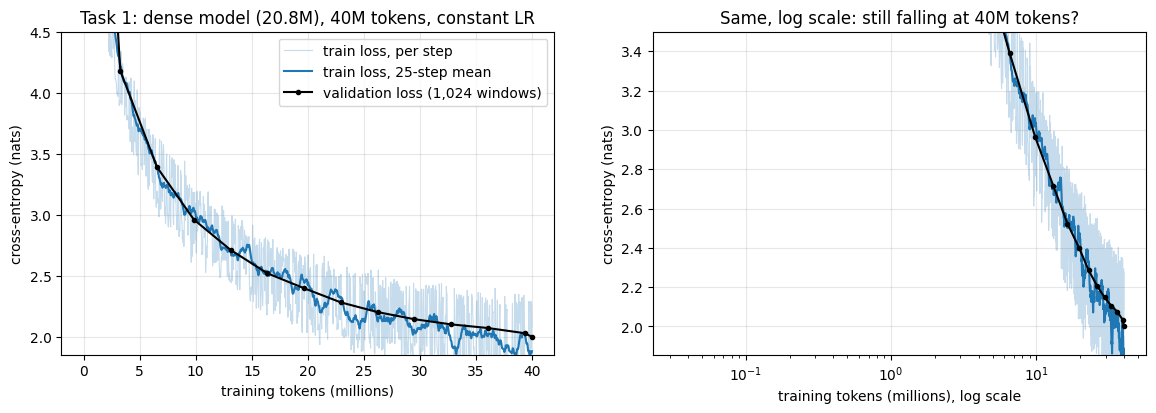

In [9]:
h = np.array([x[:3] for x in r["hist"]])                       # (steps, 3): step, tokens, train loss
vh = np.array(r["val_hist"])                                   # (evals, 3): step, tokens, validation loss
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, logx in zip(ax, [False, True]):
    a.plot(h[:, 1] / 1e6, h[:, 2], color="C0", alpha=0.25, lw=0.8, label="train loss, per step")
    a.plot(h[:, 1] / 1e6, smooth(h[:, 2]), color="C0", label="train loss, 25-step mean")
    a.plot(vh[:, 1] / 1e6, vh[:, 2], "o-", color="k", ms=3, label="validation loss (1,024 windows)")
    a.set_xlabel("training tokens (millions)" + (", log scale" if logx else ""))
    a.set_ylabel("cross-entropy (nats)")
    a.grid(alpha=0.3)
    if logx:
        a.set_xscale("log"); a.set_ylim(vh[-1, 2] - 0.15, 3.5); a.set_title("Same, log scale: still falling at 40M tokens?")
    else:
        a.set_ylim(vh[-1, 2] - 0.15, 4.5); a.set_title("Task 1: dense model (20.8M), 40M tokens, constant LR")
ax[0].legend()
savefig("dense_phaseA")

**Observations (§4).**

* The dense model reached a validation loss of **2.0041** after 40M tokens (1,220 steps), inside the predicted 2.0–2.1.
  It ran at 75,984 tokens/s with a peak of 10.36 GiB, and took 9.2 minutes on the L4.
* **It is still learning at the conversion point.** Validation loss fell by 0.10 over the last 7.2M tokens
  (2.1056 → 2.0758 → 2.0337 → 2.0041), and the log-scale plot shows no flattening. That makes it the mid-training
  checkpoint the conversion needs: there is loss left to gain, and the learning rate has not been decayed.
* The per-step training loss swings between about 1.6 and 2.3. Each step reads one contiguous stretch of about 145
  stories, so an easy or a hard stretch moves the whole batch. The 20-step mean (1.8671) is therefore rough, and the
  validation loss is the number to compare.

## 5. The MoE layer, step by step

The MoE layer keeps attention as it is and replaces the FFN with a router and $E$ experts (lesson §3). For the
$N = B \cdot T$ tokens of a batch:

| step | operation | shape |
|---|---|---|
| 1. score | $z = x W_r^\top$ in fp32, $s = \sigma(z)$ | $(N, E)$ |
| 2. choose | top-$k$ of $s + b$ (the bias $b$ is used only here) | $(N, k)$ indices |
| 3. weigh | $g = s_\text{chosen} / \sum s_\text{chosen} \times 4$ | $(N, k)$ |
| 4. dispatch | sort the $A = N k$ (token, expert) pairs by expert id → each expert's rows are contiguous | $(A, D)$ |
| 5. compute | expert $e$ runs once, on its block of $c_e$ rows (any $c_e$: **dropless**) | $(c_e, D)$ |
| 6. combine | multiply by $g$ and scatter-add back to each token's slot | $(N, D)$ |

$$y = \sum_{i \in \text{top-}k} g_i\, E_i(x), \qquad E_i(x) = W^\text{down}_i\big(\text{SiLU}(W^\text{gate}_i x) \odot W^\text{up}_i x\big)$$

**Why sort.** A GPU is fast at one big matrix product and slow at many tiny ones. After sorting, expert $e$'s tokens
form one block, so each expert is one matrix product. Example (doubt file, §1.5): chosen experts
`[2, 0, 2, 1, 0, 2]` → sorted order `[t1, t4 | t3 | t0, t2, t5]`, counts `[2, 1, 3]`.

**Balancing (our main recipe = DeepSeek-V3's).**

* **Bias**, $\gamma = 0.001$: after every step each expert's bias moves by $\pm 0.001$ towards the mean load, counted over
  the whole batch of 32,768 tokens. It changes *which* experts are chosen and never touches the gradient.
* **Sequence-level auxiliary loss**, $\alpha = 10^{-4}$: $\alpha E \sum_i f_i P_i$ computed inside each sequence of
  512 tokens, then averaged. With sigmoid scores, $P_i$ is the score normalised over the experts, as in DeepSeek-V3.
  This is a small safety net against one sequence piling onto one expert.

**Dead expert** (our threshold): an expert whose load is below 1% of the even load. With 32,768 tokens × 4 = 131,072
assignments per batch, the even load is 4,096, so "dead" means fewer than 41 tokens.

**Prediction for a freshly initialised MoE** (router std $0.1/\sqrt{384}$, and the router input is RMS-normalised,
so the logits have std ≈ 0.1). The sigmoid scores should be ≈ 0.5 with a std of about 0.025. Each of the 4 weights
should then be ≈ 1 (= 4 × ¼). The loads should be fairly even (MaxVio well below 1), because nothing has been learned
yet.

In [10]:
torch.manual_seed(0)
moe_demo = LM(MOE).cuda()
cap = {}
hook = moe_demo.blocks[5].ffn.register_forward_hook(lambda mod, inp, out: cap.__setitem__("x", inp[0].detach()))
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    moe_demo(val_t[:64, :-1])                                  # 64 windows x 512 tokens through the whole model
hook.remove()
layer5 = moe_demo.blocks[5].ffn
loads5 = layer5.last_counts.cpu().numpy()                      # (32,) assignments per expert in this batch
with torch.no_grad():
    xin = cap["x"][0].float()                                  # (T, D) input of layer 5's MoE, first window
    _, ti, tw = layer5.route(xin)                              # (T, k), (T, k)
    sc = torch.sigmoid(F.linear(xin, layer5.router))           # (T, E) sigmoid scores
print("layer 5 of a freshly initialised MoE, first 10 tokens of a validation story:")
for t in range(10):
    print(f"  token {decode([val_t[0, t].item()])!r:12s} -> experts {ti[t].tolist()}, sigmoid scores "
          f"{[round(v, 3) for v in sc[t, ti[t]].tolist()]}, weights {[round(v, 3) for v in tw[t].tolist()]} (sum {tw[t].sum():.2f})")
print(f"sigmoid scores, all 512 tokens x 32 experts: mean {sc.mean():.4f}, std {sc.std():.4f}")
print(f"loads of the 32 experts over 64 x 512 tokens x k = 4 = {loads5.sum():,} assignments (even load {loads5.mean():.0f}): "
      f"min {loads5.min()}, max {loads5.max()}, MaxVio {maxvio(loads5):.3f}, dead (< 1% of even) {dead_experts(loads5)}")
del moe_demo; gc.collect(); torch.cuda.empty_cache()

layer 5 of a freshly initialised MoE, first 10 tokens of a validation story:
  token 'Spot'       -> experts [24, 7, 8, 21], sigmoid scores [0.567, 0.545, 0.54, 0.531], weights [1.039, 0.999, 0.99, 0.972] (sum 4.00)
  token '.'          -> experts [24, 21, 29, 8], sigmoid scores [0.578, 0.559, 0.543, 0.541], weights [1.041, 1.007, 0.977, 0.975] (sum 4.00)
  token ' Spot'      -> experts [24, 4, 8, 7], sigmoid scores [0.565, 0.542, 0.539, 0.537], weights [1.035, 0.994, 0.987, 0.984] (sum 4.00)
  token ' saw'       -> experts [24, 8, 21, 4], sigmoid scores [0.562, 0.542, 0.536, 0.536], weights [1.032, 0.997, 0.986, 0.985] (sum 4.00)
  token ' the'       -> experts [24, 21, 8, 30], sigmoid scores [0.582, 0.571, 0.537, 0.536], weights [1.046, 1.026, 0.965, 0.963] (sum 4.00)
  token ' shiny'     -> experts [24, 21, 6, 4], sigmoid scores [0.557, 0.545, 0.535, 0.527], weights [1.029, 1.008, 0.988, 0.975] (sum 4.00)
  token ' car'       -> experts [24, 21, 8, 6], sigmoid scores [0.561, 0.556, 

**Observations (§5).**

* **Scores and weights came out as predicted.** The sigmoid scores have mean 0.5006 and std 0.0247 (predicted 0.5 and
  0.025). Each token's 4 weights lie between 0.96 and 1.05 and add up to 4.00.
* **Prediction wrong: the loads are far from even.** In layer 5 one expert received 16,613 of the 131,072
  assignments, 4.1× the even load of 4,096. That gives MaxVio **3.06**, not "well below 1". Expert 24 is among the 4
  chosen experts of all 10 example tokens, and it is the first choice for 9 of them.
* **Why.** The scores differ more *between experts* than *between tokens*. Expert 24 scores 0.56–0.58 for 9 of the 10
  tokens, while a token's 4th-best score is only about 0.53. The most likely cause is a large common direction shared
  by all the inputs to layer 5, because the residual stream of an untrained transformer carries a component that is
  the same at every position. Whichever router row happens to align with it wins for nearly every token. We did not
  measure that direction directly. The practical consequence is that an MoE is imbalanced from its very first step,
  before any feedback loop has run, so balancing has to act from step 1.

## 6. Task 2: convert the dense model into an MoE (upcycling)

Everything outside the FFNs (embedding, attention, norms) is copied unchanged. Each layer's FFN is replaced by
experts built from its weights, plus a new router (small random init, bias 0). The lesson (§15) lists three ways to
build the experts. With a dense FFN of 4 neurons whose contributions to the output are $[a, b, c, d]$, the dense output
is $a + b + c + d$:

| method | each expert starts as | what the MoE computes at step 0 |
|---|---|---|
| **copy** (sparse upcycling, Komatsuzaki et al. 2022) | the whole FFN | top-1, weight 1: exactly $a + b + c + d$ |
| **partition** (Qwen1.5-MoE) | one slice of neurons, e.g. $[a]$; 8 clones per slice | $\sum$ (chosen slices) × weight ≈ 1 each: exact only if the 4 chosen experts are one clone of each slice |
| **drop-upcycling** $r$ (Nakamura et al. 2025) | a slice with a random fraction $r$ of its neurons redrawn from $\mathcal{N}(\mu_W, \sigma_W)$ of the dense matrix | partition plus new random neurons: a larger jump, but clones start *different* |

**Why the routed scaling factor is 4.** The router's weights for a token add up to one. Without a factor, 4 slices at
weight ¼ give ¼ of the dense FFN. With a factor of $k = 4$ they give exactly the FFN (lesson §7: the factor "restores
the size of the layer's output" when experts are small).

**Why redraw neurons at all.** Clones of one slice are identical. The router cannot tell them apart, and their
gradients are almost the same, so they stay alike. This is the "collapse along clone families" that the lesson
describes for the Lightning LM. Redrawing a different random half in every clone gives each one its own neurons from
step 0. Drop-upcycling found $r = 0.5$ best, so it is our main run.

**Predictions for the loss right after conversion** (before any training):

| variant | experts × width, top-k | prediction |
|---|---|---|
| copy | 8 × 1,024, top-1 | **= dense loss** (difference ≈ bf16 noise, < 0.005) |
| partition r = 0 | 32 × 256, top-4 | a jump: a random router covers on average 2.82 of 4 slices, all 4 for only 11.4% of tokens (§1.7) |
| drop r = 0.25, 0.5 | 32 × 256, top-4 | larger jumps, growing with $r$ |
| drop r = 1.0 | 32 × 256, top-4 | the largest: the FFNs are random, only attention and embeddings are kept |

The cell also measures how many distinct dense slices the router picks per token, to compare with the 2.82 / 11.4%
prediction. The router is not perfectly random: hidden states share common directions, so it may prefer some experts
for all tokens.

dense model at the conversion point: validation loss 2.0041 (1,024 windows)

copy 8x1024 top-1 : val loss right after conversion 2.0040 (jump -0.0000); distinct dense slices per token 1.000 of 1 (random router: 1); tokens with all 1 slices 100.0%; load MaxVio (mean over layers) 1.32
partition r=0     : val loss right after conversion 2.1930 (jump +0.1889); distinct dense slices per token 2.846 of 4 (random router: 2.818); tokens with all 4 slices 12.5%; load MaxVio (mean over layers) 1.41
drop r=0.25       : val loss right after conversion 2.3267 (jump +0.3227); distinct dense slices per token 2.846 of 4 (random router: 2.818); tokens with all 4 slices 12.4%; load MaxVio (mean over layers) 1.43
drop r=0.5        : val loss right after conversion 2.7429 (jump +0.7389); distinct dense slices per token 2.847 of 4 (random router: 2.818); tokens with all 4 slices 12.3%; load MaxVio (mean over layers) 1.48
drop r=1.0        : val loss right after conversion 7.5300 (jump +5.5259); distinct de

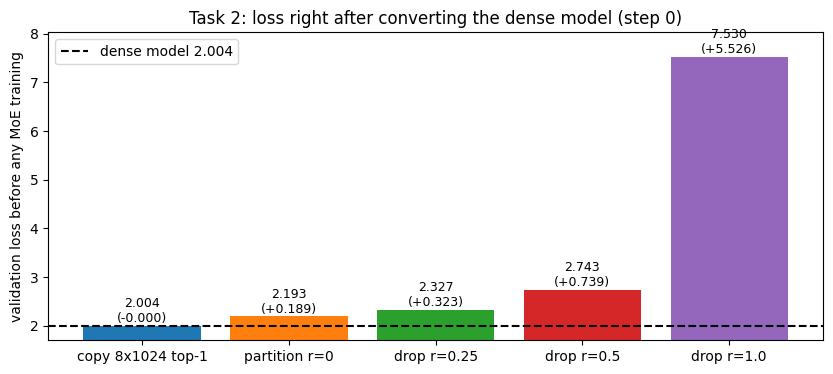

In [11]:
VARIANTS = {                                                   # name: (config, method, redraw fraction r)
    "copy 8x1024 top-1": (COPY, "copy", 0.0),
    "partition r=0":     (MOE, "partition", 0.0),
    "drop r=0.25":       (MOE, "partition", 0.25),
    "drop r=0.5":        (MOE, "partition", 0.5),
    "drop r=1.0":        (MOE, "partition", 1.0),
}
DENSE_VAL = evaluate(dense, val_t, N_VAL_WINDOWS)
print(f"dense model at the conversion point: validation loss {DENSE_VAL:.4f} (1,024 windows)\n")
STEP0 = {}
for name, (c, meth, rr) in VARIANTS.items():
    m, fam = upcycle(dense, c, meth, rr, seed=0)
    v = evaluate(m, val_t, N_VAL_WINDOWS)
    topi, _, _ = routing_probe(m, val_t, 64)                   # list over layers of (32768, k) chosen experts
    famt = fam[torch.stack(topi)]                              # (L, N, k) dense slice of each chosen expert
    srt = famt.sort(-1).values
    distinct = (1 + (srt[..., 1:] != srt[..., :-1]).sum(-1)).float()            # (L, N) distinct slices per token
    S = int(fam.max()) + 1
    loads = np.stack([torch.bincount(t.flatten(), minlength=c.n_expert).numpy() for t in topi])   # (L, E)
    STEP0[name] = dict(val=v, jump=v - DENSE_VAL, slices=S, distinct=distinct.mean().item(),
                       all_slices=(distinct == S).float().mean().item(), maxvio=float(maxvio(loads).mean()),
                       dead=int(dead_experts(loads).sum()))
    print(f"{name:18s}: val loss right after conversion {v:.4f} (jump {v - DENSE_VAL:+.4f}); distinct dense slices "
          f"per token {STEP0[name]['distinct']:.3f} of {S} (random router: {'2.818' if S == 4 else '1'}); tokens with all "
          f"{S} slices {STEP0[name]['all_slices']:.1%}; load MaxVio (mean over layers) {STEP0[name]['maxvio']:.2f}")
    del m; gc.collect(); torch.cuda.empty_cache()
RESULTS["step0"] = STEP0; RESULTS["dense_val_at_conversion"] = DENSE_VAL; save_results()

names = list(STEP0)
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(names, [STEP0[n]["val"] for n in names], color=["C0", "C1", "C2", "C3", "C4"])
ax.axhline(DENSE_VAL, color="k", ls="--", label=f"dense model {DENSE_VAL:.3f}")
for b, n in zip(bars, names):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"{STEP0[n]['val']:.3f}\n({STEP0[n]['jump']:+.3f})",
            ha="center", va="bottom", fontsize=9)
ax.set_ylim(DENSE_VAL - 0.3, max(STEP0[n]["val"] for n in names) + 0.5)
ax.set_ylabel("validation loss before any MoE training"); ax.legend()
ax.set_title("Task 2: loss right after converting the dense model (step 0)")
savefig("conversion_step0")

**The router on real text right after the conversion.** The same layer-5 view as in §5, now for the drop r = 0.5 MoE.
"slice" is the dense slice an expert came from (expert id mod 4).

In [12]:
m, fam = upcycle(dense, MOE, "partition", 0.5, seed=0)
cap = {}
hook = m.blocks[5].ffn.register_forward_hook(lambda mod, inp, out: cap.__setitem__("x", inp[0].detach()))
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    m(val_t[:1, :-1])
hook.remove()
with torch.no_grad():
    _, ti, tw = m.blocks[5].ffn.route(cap["x"][0].float())
for t in range(10):
    print(f"  token {decode([val_t[0, t].item()])!r:12s} -> experts {ti[t].tolist()}, slices {fam[ti[t].cpu()].tolist()}, "
          f"weights {[round(v, 3) for v in tw[t].tolist()]}")
del m; gc.collect(); torch.cuda.empty_cache()

  token 'Spot'       -> experts [8, 16, 2, 18], slices [0, 0, 2, 2], weights [1.026, 0.994, 0.992, 0.988]
  token '.'          -> experts [22, 4, 17, 8], slices [2, 0, 1, 0], weights [1.008, 1.001, 0.997, 0.994]
  token ' Spot'      -> experts [19, 2, 8, 11], slices [3, 2, 0, 3], weights [1.013, 1.006, 0.997, 0.984]
  token ' saw'       -> experts [31, 9, 10, 29], slices [3, 1, 2, 1], weights [1.004, 1.003, 0.998, 0.995]
  token ' the'       -> experts [22, 10, 16, 26], slices [2, 2, 0, 2], weights [1.013, 1.003, 0.994, 0.99]
  token ' shiny'     -> experts [11, 13, 8, 26], slices [3, 1, 0, 2], weights [1.06, 0.987, 0.982, 0.971]
  token ' car'       -> experts [17, 6, 24, 18], slices [1, 2, 0, 2], weights [1.026, 0.997, 0.996, 0.981]
  token ' and'       -> experts [16, 11, 8, 2], slices [0, 3, 0, 2], weights [1.009, 1.006, 1.002, 0.983]
  token ' said'      -> experts [28, 31, 25, 18], slices [0, 3, 1, 2], weights [1.025, 0.995, 0.992, 0.988]
  token ','          -> experts [15, 23, 

**Observations (§6).**

| variant | val loss at step 0 | jump | distinct slices per token (random: 2.82) | tokens with all 4 slices (random: 11.4%) |
|---|--:|--:|--:|--:|
| copy 8 × 1,024, top-1 | 2.0040 | −0.0000 | 1 of 1 | 100% |
| partition r = 0 | 2.1930 | +0.189 | 2.846 | 12.5% |
| drop r = 0.25 | 2.3267 | +0.323 | 2.846 | 12.4% |
| **drop r = 0.5** (main run) | 2.7429 | +0.739 | 2.847 | 12.3% |
| drop r = 1.0 | 7.5300 | +5.526 | 2.844 | 12.6% |

* **Copy + top-1 reproduces the dense model**, as predicted: 2.0040 against 2.0041. The function is preserved even
  though the router is random, because whichever copy is chosen, it is the dense FFN with weight 1.
* **Partition jumps by 0.189, and the router is the reason.** The new router covers 2.85 of the 4 slices per token,
  and all 4 for only 12.5% of tokens. That is almost exactly the random-router prediction of §1.7 (2.82 and 11.4%):
  the router cannot know which expert came from which slice. The layer-5 printout shows this on real text. 'Spot' gets
  experts from slices [0, 0, 2, 2], so slices 0 and 2 count twice and slices 1 and 3 are missing.
* **The jump grows with r**, as predicted: +0.323, +0.739, +5.526. At r = 1.0 the loss is 7.53, which gives back 78%
  of what the dense training gained (from 9.07 to 2.00). Keeping attention and embeddings is not enough. Random
  experts as large as the trained ones add noise to the residual stream in every layer, and the noise reaches every
  layer above.

## 7. Task 3: keep training the MoE, and show the loss keeps falling

Three runs read **the same 20M new tokens** (tokens 40M → 60M), with the same schedule:

| run | starts from | parameters (total / active) |
|---|---|---|
| **dense continued** (control) | the 40M dense checkpoint | 20.8M / 20.8M |
| **upcycled MoE**, drop r = 0.5 (main) | the 40M dense checkpoint, converted in §6 | 103.5M / 21.0M |
| **MoE from scratch** (control) | random weights, trained on tokens 0 → 60M (all of it) | 103.5M / 21.0M |

**Schedule for every phase-B run.** A fresh AdamW, a 2% warm-up (12 steps), a constant $1.5 \times 10^{-3}$, then a
linear decay to $1.5 \times 10^{-4}$ over the last 20% of the steps (the "D" of WSD). The optimizer is fresh because
the experts and routers are new tensors with no Adam history. The dense control gets the same restart, so the only
difference between the two is the MoE.

**What "continues to train and reduce loss" needs to show.** The MoE's validation loss must fall from its value right
after the conversion, and it must get below the dense model's loss at the conversion point. The useful comparison is
against the *dense control*: part of every phase-B decrease comes from more data and from the final LR decay, and
the control shows how much.

**Predictions.**
1. *Dense continued*: a smooth continuation of phase A, with an extra drop during the final LR decay.
2. *Upcycled MoE*: starts above the dense loss (the jump measured in §6), crosses below the conversion-point loss within
   the first few million tokens, and ends **below dense continued**. It has the same compute per token and 5× the
   parameters (lesson §5: capacity follows the total, cost follows the active).
3. *MoE from scratch* (60M tokens): ends above the upcycled MoE. The lesson's §15 says a from-scratch MoE needs
   between 25% (OLMoE) and 120% (sparse upcycling paper) of the dense budget *extra* to catch up. Our extra budget is
   50% (20M on top of 40M), so it could go either way. A weaker prediction: it ends close to the upcycled MoE.
4. *Speed*: the MoE is slower per token than the dense model despite equal FLOPs. Each layer runs 32 small expert
   products in a Python loop and synchronises once to read the expert counts. Guess: 0.6–0.8× the dense speed.

`RUN_SCRATCH = False` skips the from-scratch run (55 minutes measured).

In [13]:
RUN_SCRATCH = True

# 7a. dense continued (control)
dense_c = LM(DENSE).cuda()
dense_c.load_state_dict(torch.load("dense_phaseA.pt"))
RESULTS["dense_continued"] = train(dense_c, train_tok, val_t, start_token=CONVERT_AT, n_tokens=MOE_TOKENS,
                                   batch=BATCH, eval_every=50, log_every=50, label="dense continued")
save_results()
del dense_c; gc.collect(); torch.cuda.empty_cache()

  [dense continued] 610 steps of 32,768 tokens, tokens 40M -> 60M;  val loss before the first step 2.0041
  [dense continued] step     1/610  tokens  40.01M  train loss 2.1137  grad norm 0.267  lr 1.25e-04
  [dense continued] step    50/610  tokens  41.62M  train loss 2.2182  grad norm 0.249  lr 1.50e-03   val 2.0157
  [dense continued] step   100/610  tokens  43.25M  train loss 1.7213  grad norm 0.246  lr 1.50e-03   val 1.9977
  [dense continued] step   150/610  tokens  44.89M  train loss 2.2005  grad norm 0.338  lr 1.50e-03   val 1.9909
  [dense continued] step   200/610  tokens  46.53M  train loss 1.6141  grad norm 0.300  lr 1.50e-03   val 1.9594
  [dense continued] step   250/610  tokens  48.17M  train loss 2.2395  grad norm 0.334  lr 1.50e-03   val 1.9619
  [dense continued] step   300/610  tokens  49.81M  train loss 2.2298  grad norm 0.254  lr 1.50e-03   val 1.9415
  [dense continued] step   350/610  tokens  51.45M  train loss 1.6983  grad norm 0.364  lr 1.50e-03   val 1.9314
  [

In [14]:
# 7b. the upcycled MoE (main run): drop-upcycling r = 0.5, sigmoid router, bias 1e-3 + sequence aux 1e-4
moe_main, fam_main = upcycle(dense, MOE, "partition", 0.5, seed=0)
sim_init = clone_similarity(moe_main, fam_main)
RESULTS["moe_main"] = train(moe_main, train_tok, val_t, start_token=CONVERT_AT, n_tokens=MOE_TOKENS,
                            batch=BATCH, eval_every=50, log_every=50, label="upcycled MoE (drop r=0.5)")
sim_end = clone_similarity(moe_main, fam_main)
RESULTS["moe_main"].update(clone_sim_init=sim_init, clone_sim_end=sim_end)
torch.save(moe_main.state_dict(), "moe_main.pt")
save_results()
print(f"\ncosine similarity between clones of the same dense slice (mean over layers): at conversion "
      f"{np.nanmean(sim_init[0]):.3f}, after 20M tokens {np.nanmean(sim_end[0]):.3f}")
print(f"cosine similarity between experts from different slices:                 at conversion "
      f"{np.nanmean(sim_init[1]):.3f}, after 20M tokens {np.nanmean(sim_end[1]):.3f}")

  [upcycled MoE (drop r=0.5)] 610 steps of 32,768 tokens, tokens 40M -> 60M;  val loss before the first step 2.7429
  [upcycled MoE (drop r=0.5)] step     1/610  tokens  40.01M  train loss 2.8589  grad norm 0.907  lr 1.25e-04  MaxVio (mean over layers) 1.55
  [upcycled MoE (drop r=0.5)] step    50/610  tokens  41.62M  train loss 2.3453  grad norm 0.257  lr 1.50e-03  MaxVio (mean over layers) 3.28   val 2.1577
  [upcycled MoE (drop r=0.5)] step   100/610  tokens  43.25M  train loss 1.8417  grad norm 0.261  lr 1.50e-03  MaxVio (mean over layers) 4.19   val 2.1001
  [upcycled MoE (drop r=0.5)] step   150/610  tokens  44.89M  train loss 2.2788  grad norm 0.386  lr 1.50e-03  MaxVio (mean over layers) 4.26   val 2.0774
  [upcycled MoE (drop r=0.5)] step   200/610  tokens  46.53M  train loss 1.6791  grad norm 0.270  lr 1.50e-03  MaxVio (mean over layers) 4.19   val 2.0269
  [upcycled MoE (drop r=0.5)] step   250/610  tokens  48.17M  train loss 2.3038  grad norm 0.308  lr 1.50e-03  MaxVio (mea

In [15]:
# 7c. the same MoE trained from scratch on all 60M tokens (control)
if RUN_SCRATCH:
    torch.manual_seed(1337)
    moe_s = LM(MOE).cuda()
    RESULTS["moe_scratch"] = train(moe_s, train_tok, val_t, start_token=0, n_tokens=CONVERT_AT + MOE_TOKENS,
                                   batch=BATCH, eval_every=100, log_every=100, label="MoE from scratch")
    save_results()
    del moe_s; gc.collect(); torch.cuda.empty_cache()

  [MoE from scratch] 1830 steps of 32,768 tokens, tokens 0M -> 60M;  val loss before the first step 9.0932
  [MoE from scratch] step     1/1830  tokens   0.03M  train loss 9.0866  grad norm 2.932  lr 4.05e-05  MaxVio (mean over layers) 1.42
  [MoE from scratch] step   100/1830  tokens   3.28M  train loss 3.8012  grad norm 0.917  lr 1.50e-03  MaxVio (mean over layers) 3.69   val 4.0592
  [MoE from scratch] step   200/1830  tokens   6.55M  train loss 3.1290  grad norm 0.444  lr 1.50e-03  MaxVio (mean over layers) 3.09   val 3.3155
  [MoE from scratch] step   300/1830  tokens   9.83M  train loss 2.6449  grad norm 0.499  lr 1.50e-03  MaxVio (mean over layers) 2.58   val 2.8733
  [MoE from scratch] step   400/1830  tokens  13.11M  train loss 2.3428  grad norm 0.305  lr 1.50e-03  MaxVio (mean over layers) 1.18   val 2.6233
  [MoE from scratch] step   500/1830  tokens  16.38M  train loss 2.6278  grad norm 0.275  lr 1.50e-03  MaxVio (mean over layers) 0.72   val 2.4299
  [MoE from scratch] ste

### 7.1 The result: loss across the conversion

The left plot shows the whole run (phase A in black). The right plot zooms into phase B. The dashed line marks the
conversion.

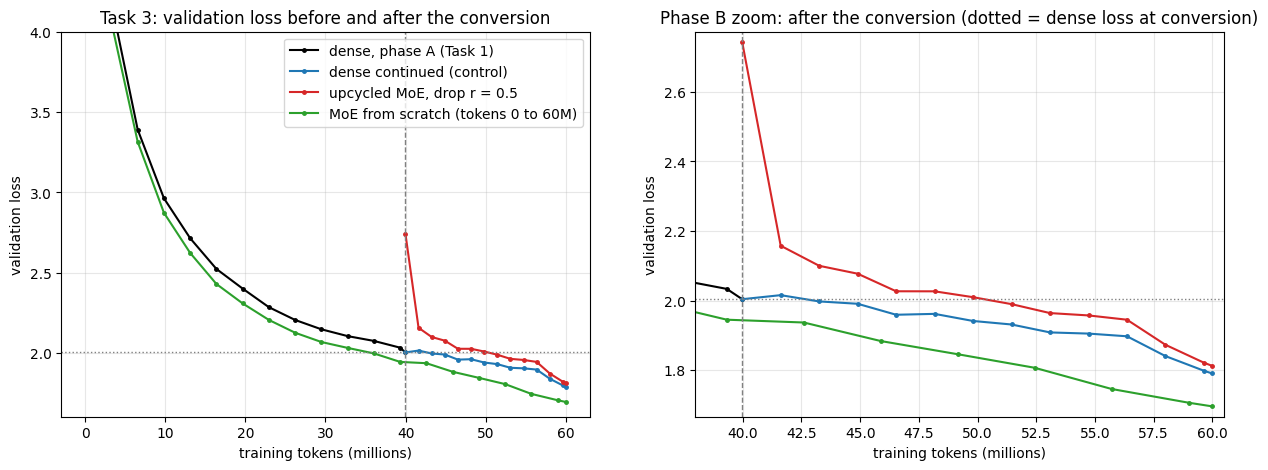

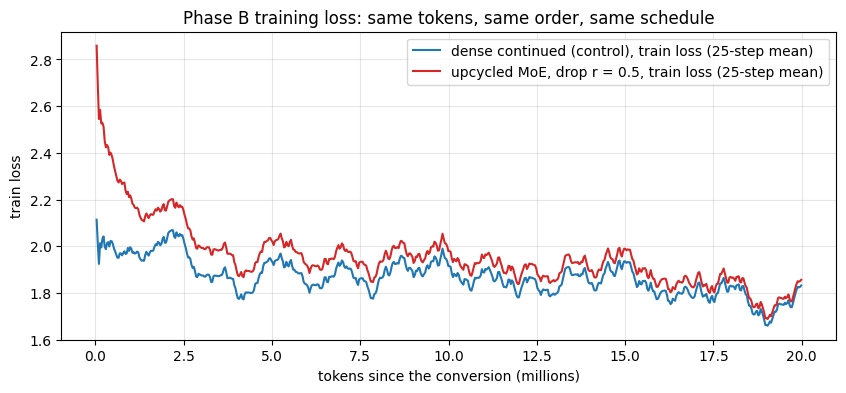

In [16]:
RUNS7 = [("dense_continued", "C0", "dense continued (control)"), ("moe_main", "C3", "upcycled MoE, drop r = 0.5"),
         ("moe_scratch", "C2", "MoE from scratch (tokens 0 to 60M)")]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, zoom in zip(axes, [False, True]):
    vh = np.array(RESULTS["dense_A"]["val_hist"])
    ax.plot(vh[:, 1] / 1e6, vh[:, 2], "o-", color="k", ms=2.5, label="dense, phase A (Task 1)")
    for key, col, lab in RUNS7:
        if key in RESULTS:
            vh = np.array(RESULTS[key]["val_hist"])
            ax.plot(vh[:, 1] / 1e6, vh[:, 2], "o-", color=col, ms=2.5, label=lab)
    ax.axvline(CONVERT_AT / 1e6, color="grey", ls="--", lw=1)
    ax.axhline(DENSE_VAL, color="grey", ls=":", lw=1)
    ax.set_xlabel("training tokens (millions)"); ax.set_ylabel("validation loss"); ax.grid(alpha=0.3)
    if zoom:
        ph = [v for key, _, _ in RUNS7 if key in RESULTS for (_, t, v) in RESULTS[key]["val_hist"] if t >= CONVERT_AT]
        ax.set_xlim(CONVERT_AT / 1e6 - 2, (CONVERT_AT + MOE_TOKENS) / 1e6 + 0.5)
        ax.set_ylim(min(ph) - 0.03, max(ph) + 0.03)
        ax.set_title("Phase B zoom: after the conversion (dotted = dense loss at conversion)")
    else:
        ax.set_ylim(DENSE_VAL - 0.4, 4.0)
        ax.set_title("Task 3: validation loss before and after the conversion")
        ax.legend()
savefig("task3_loss_across_conversion")

fig, ax = plt.subplots(figsize=(10, 4))
for key, col, lab in RUNS7[:2]:
    h = np.array([x[:3] for x in RESULTS[key]["hist"]])
    ax.plot((h[:, 1] - CONVERT_AT) / 1e6, smooth(h[:, 2]), color=col, label=lab + ", train loss (25-step mean)")
ax.set_xlabel("tokens since the conversion (millions)"); ax.set_ylabel("train loss"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Phase B training loss: same tokens, same order, same schedule")
savefig("task3_train_loss_phaseB")

In [17]:
def row(name, res, first_tok):
    "One line of the results table for a run dict produced by train()."
    return (f"{name:34s} {first_tok / 1e6:5.1f}M -> {(res['start_token'] + res['steps'] * res['tokens_per_step']) / 1e6:5.1f}M "
            f"{res['val_start']:10.4f} {res['final_val']:10.4f} {res['final_train']:10.4f} {res['tok_per_s']:11,.0f} "
            f"{res['peak_gib']:8.2f} {res['wall_s'] / 60:7.1f}")
print(f"{'run':34s} {'tokens':16s} {'val start':>10s} {'val end':>10s} {'train end':>10s} {'tokens/s':>11s} "
      f"{'peak GiB':>8s} {'minutes':>7s}")
print(row("dense, phase A", RESULTS["dense_A"], 0))
for key, _, lab in RUNS7:
    if key in RESULTS:
        print(row(lab, RESULTS[key], RESULTS[key]["start_token"]))
print("(val start = before the first step, val end = after the last step; both on all 1,024 validation windows)")

dc, mm = RESULTS["dense_continued"], RESULTS["moe_main"]
vh = np.array(mm["val_hist"])
print(f"\nupcycled MoE, validation loss every 50 steps (tokens since the conversion -> loss):")
print("  " + ",  ".join(f"{(t - CONVERT_AT) / 1e6:.1f}M: {v:.3f}" for _, t, v in vh))
below = [(t - CONVERT_AT) / 1e6 for _, t, v in vh if v < DENSE_VAL]
print(f"first evaluation below the dense loss at the conversion ({DENSE_VAL:.4f}): "
      f"{'after %.1fM tokens' % below[0] if below else 'never'}")
dec = np.sum(np.diff(vh[:, 2]) < 0)
print(f"evaluations lower than the previous one: {dec} of {len(vh) - 1}")
print(f"\nfinal validation loss: dense continued {dc['final_val']:.4f}, upcycled MoE {mm['final_val']:.4f} "
      f"-> MoE minus dense = {mm['final_val'] - dc['final_val']:+.4f}")
print(f"decrease during phase B (dense loss at conversion -> end): dense continued {DENSE_VAL - dc['final_val']:.4f}, "
      f"upcycled MoE {DENSE_VAL - mm['final_val']:.4f}")
print(f"speed: MoE / dense = {mm['tok_per_s'] / dc['tok_per_s']:.2f}x; peak memory: MoE {mm['peak_gib']:.2f} GiB vs dense "
      f"{dc['peak_gib']:.2f} GiB")
if "moe_scratch" in RESULTS:
    print(f"MoE from scratch after the same 60M tokens: {RESULTS['moe_scratch']['final_val']:.4f} "
          f"(upcycled minus scratch = {mm['final_val'] - RESULTS['moe_scratch']['final_val']:+.4f})")

run                                tokens            val start    val end  train end    tokens/s peak GiB minutes
dense, phase A                       0.0M ->  40.0M     9.0736     2.0041     1.8671      75,984    10.36     9.2
dense continued (control)           40.0M ->  60.0M     2.0041     1.7911     1.8218      75,869    10.52     4.8
upcycled MoE, drop r = 0.5          40.0M ->  60.0M     2.7429     1.8130     1.8452      18,460    17.31    18.9
MoE from scratch (tokens 0 to 60M)   0.0M ->  60.0M     9.0932     1.6963     1.7216      18,704    17.70    54.7
(val start = before the first step, val end = after the last step; both on all 1,024 validation windows)

upcycled MoE, validation loss every 50 steps (tokens since the conversion -> loss):
  0.0M: 2.743,  1.6M: 2.158,  3.3M: 2.100,  4.9M: 2.077,  6.6M: 2.027,  8.2M: 2.027,  9.8M: 2.010,  11.5M: 1.990,  13.1M: 1.964,  14.7M: 1.957,  16.4M: 1.945,  18.0M: 1.873,  19.7M: 1.822,  20.0M: 1.813
first evaluation below the dense loss

**Observations (§7).**

**The task's requirement is met.** After the conversion, the upcycled MoE's validation loss fell at every one of its
13 evaluations, from 2.7429 to **1.8130** (−0.930). It went below the dense model's loss at the conversion point
(2.0041) after 11.5M tokens, and it ended 0.191 below it.

| run, same tokens 40M → 60M | val before | val after | change |
|---|--:|--:|--:|
| dense continued (control) | 2.0041 | **1.7911** | −0.213 |
| upcycled MoE, drop r = 0.5 | 2.7429 | **1.8130** | −0.930 |
| MoE from scratch (tokens 0 → 60M) | 9.0932 | **1.6963** | |

Against the predictions:

1. **Dense continued** behaved as predicted. Half of its phase-B gain came in the final learning-rate decay:
   1.8975 → 1.7911 over the last 3.6M tokens.
2. **Wrong: the upcycled MoE did not beat dense continued.** It ended **0.022 above** it. It also needed 11.5M tokens,
   not "the first few million", to get back below the conversion-point loss. The gap closed at almost every
   evaluation: 0.142 after 1.6M tokens, 0.068 after 6.6M, 0.048 after 16.4M and 0.022 at the end. So 20M tokens were
   not enough to repay the 0.74 jump from redrawing half of every expert. The §8 sweep shows that a smaller r starts
   closer and stays closer.
3. **Wrong: the MoE trained from scratch is the best model by far.** It ended 0.095 below dense continued and 0.117
   below the upcycled MoE. All three runs used about the same training compute (60M tokens × ≈125 MFLOP per token).
   It was already ahead of the dense model at equal tokens and the same constant learning rate: 1.9452 against 2.0337
   at 39.3M tokens. So the MoE design delivers what the lesson's §5 promises: more stored parameters at the same
   compute per token give a lower loss. What held the upcycled model back was the conversion, not the MoE.
4. **Wrong: speed** was 0.24× the dense model's, not 0.6–0.8× (see §12).

**When upcycling wins, and when it does not.** If the dense model already exists, its 40M tokens are a sunk cost, and
the question is what 20M *more* tokens buy. Then upcycling wins clearly: 1.813, against 2.309 for the same MoE after
its first 20M tokens from scratch (at constant learning rate, before its decay). If the dense training is counted,
upcycling loses. At the same total compute, the from-scratch MoE was lower at every evaluation of phase B, for example
1.846 against 2.010 at about 49.5M tokens. The papers in the lesson report the opposite for a while: a from-scratch
MoE needs 25–120% more compute to catch up with an upcycled one. In our run that crossover had already happened
before the conversion. The from-scratch MoE was ahead of the dense model at 40M tokens, so a model that starts from
the dense model's loss, or above it, starts behind.

**Training loss (second plot).** Both runs read the same batches in the same order, so the two curves wiggle together.
The distance between them is the effect of the model alone. It starts at 0.75 and shrinks to about 0.02.

**Inside the main MoE.** MaxVio rose from 1.55 to about 4.3 by step 150, then fell steadily to 0.42 by step 600 as
the bias accumulated (§9 explains the delay). Clones of the same slice drifted apart only a little: cosine
similarity 0.250 at the conversion and 0.217 after 20M tokens. Experts from different slices went from 0.006 to
0.014.

## 8. Which way of building the experts trains best? (5M-token sweep)

All five conversions from §6, plus the dense control, each trained on the same 5M tokens (tokens 40M → 45M, 152 steps)
with the phase-B schedule compressed to 152 steps. Balancing is the main recipe (bias + sequence aux) in every MoE.

Besides the loss, two diagnostics measure whether the clones become different:

* **Clone similarity**: the cosine similarity between experts that came from the same dense slice. Each expert is
  flattened into one vector $[W^\text{gate}, W^\text{up}, (W^\text{down})^\top]$. Identical clones give 1.0. For
  drop $r$, two clones share about $(1-r)^2$ of their neurons in the same positions, so they start at about
  $(1-r)^2$ (0.56, 0.25 and 0 for $r$ = 0.25, 0.5, 1.0). For "copy" all 8 experts are one family and start at 1.0.
* **Collapse inside clone families**: for each slice, how many of its 8 clones still receive at least 10% of the even
  load at the end. The lesson's §15 Lightning LM run lost up to 168 of 460 experts this way with hard top-k and *no*
  redraw.

**Predictions.**
* *copy*: starts exactly at the dense loss. But its 8 experts are identical and top-1 means only one is trained per
  token, so they separate slowly. It ends close to the dense control.
* *partition r = 0*: the smallest jump among the 32-expert variants. Its clones start identical, so the clone
  similarity stays high and families may collapse onto a few members.
* *drop r = 0.25 / 0.5*: bigger jumps but diverse clones. The drop-upcycling paper found r = 0.5 best over long
  training. Over only 5M tokens the variant that keeps more knowledge (smaller r) may still be ahead.
* *drop r = 1.0*: the FFNs restart from random. It should be the worst of all, probably even worse than the dense
  control.

In [18]:
SWEEP = {}
dc5 = LM(DENSE).cuda()
dc5.load_state_dict(torch.load("dense_phaseA.pt"))
SWEEP["dense continued"] = train(dc5, train_tok, val_t, start_token=CONVERT_AT, n_tokens=SWEEP_TOKENS, batch=BATCH,
                                 eval_every=25, log_every=50, label="sweep: dense continued")
del dc5
for name, (c, meth, rr) in VARIANTS.items():
    m, fam = upcycle(dense, c, meth, rr, seed=0)
    s0 = clone_similarity(m, fam)
    res = train(m, train_tok, val_t, start_token=CONVERT_AT, n_tokens=SWEEP_TOKENS, batch=BATCH,
                eval_every=25, log_every=50, label=f"sweep: {name}")
    s1 = clone_similarity(m, fam)
    res.update(family=fam.numpy(), clone_sim_init=s0, clone_sim_end=s1)
    SWEEP[name] = res
    del m; gc.collect(); torch.cuda.empty_cache()
RESULTS["sweep"] = SWEEP; save_results()

  [sweep: dense continued] 152 steps of 32,768 tokens, tokens 40M -> 45M;  val loss before the first step 2.0041
  [sweep: dense continued] step     1/152  tokens  40.01M  train loss 2.1137  grad norm 0.267  lr 5.00e-04
  [sweep: dense continued] step    50/152  tokens  41.62M  train loss 2.2248  grad norm 0.239  lr 1.50e-03   val 2.0206
  [sweep: dense continued] step   100/152  tokens  43.25M  train loss 1.7230  grad norm 0.238  lr 1.50e-03   val 2.0011
  [sweep: dense continued] step   150/152  tokens  44.89M  train loss 2.1169  grad norm 0.242  lr 2.40e-04   val 1.9240
  [sweep: dense continued] step   152/152  tokens  44.96M  train loss 1.5405  grad norm 0.204  lr 1.50e-04
  [sweep: copy 8x1024 top-1] 152 steps of 32,768 tokens, tokens 40M -> 45M;  val loss before the first step 2.0040
  [sweep: copy 8x1024 top-1] step     1/152  tokens  40.01M  train loss 2.1138  grad norm 0.262  lr 5.00e-04  MaxVio (mean over layers) 1.28
  [sweep: copy 8x1024 top-1] step    50/152  tokens  41.6

run                  val step 0   val end  vs dense  clone sim start  clone sim end MaxVio end  experts >= 10% of even load
dense continued          2.0041    1.9203          
copy 8x1024 top-1        2.0040    1.9809   +0.0606            1.000          0.940       0.02             80 of 80
partition r=0            2.1930    1.9468   +0.0266            1.000          0.944       6.69            204 of 320
drop r=0.25              2.3267    1.9701   +0.0498            0.563          0.538       6.30            231 of 320
drop r=0.5               2.7429    2.0002   +0.0799            0.250          0.244       5.18            275 of 320
drop r=1.0               7.5299    2.1103   +0.1901            0.000          0.000       3.32            279 of 320
(val step 0 = before training, val end = after it, both on 1,024 windows; clone sim = mean cosine similarity of experts from the same slice)


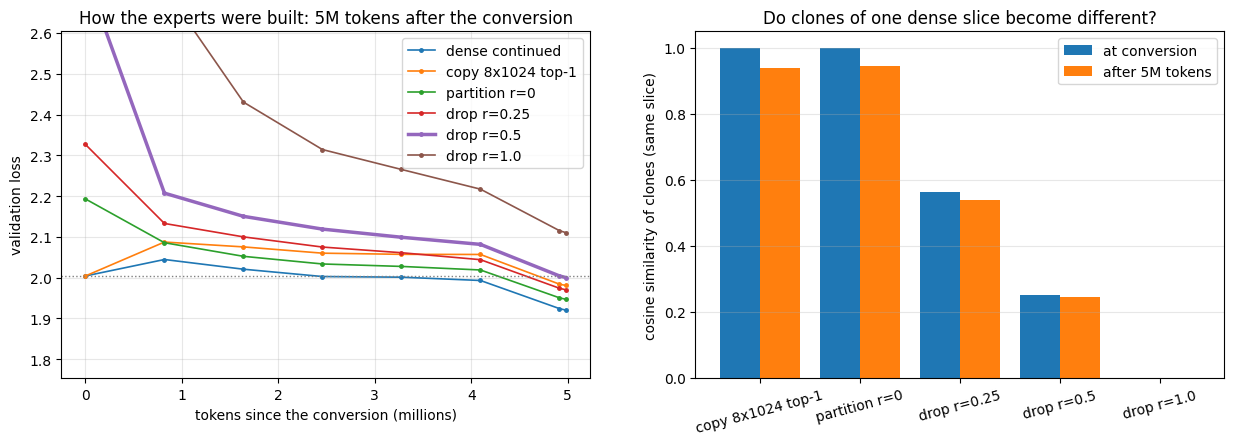

In [19]:
def family_survivors(res, frac=0.10, last=20):
    "Per run: (alive clones per family summed over layers, total clones) using loads averaged over the last steps."
    ld = res["loads"][-last:].mean(0)                          # (L, E) mean load per expert over the last steps
    alive = ld >= frac * ld.mean(1, keepdims=True)             # (L, E)
    return int(alive.sum()), alive.size

print(f"{'run':20s} {'val step 0':>10s} {'val end':>9s} {'vs dense':>9s} {'clone sim start':>16s} {'clone sim end':>14s} "
      f"{'MaxVio end':>10s} {'experts >= 10% of even load':>28s}")
for name, res in SWEEP.items():
    if res["loads"] is None:
        print(f"{name:20s} {res['val_start']:10.4f} {res['final_val']:9.4f} {'':>9s}")
        continue
    a, n = family_survivors(res)
    mv = maxvio(res["loads"][-20:].mean(0)).mean()
    print(f"{name:20s} {res['val_start']:10.4f} {res['final_val']:9.4f} {res['final_val'] - SWEEP['dense continued']['final_val']:+9.4f} "
          f"{np.nanmean(res['clone_sim_init'][0]):16.3f} {np.nanmean(res['clone_sim_end'][0]):14.3f} {mv:10.2f} "
          f"{a:>14d} of {n}")
print("(val step 0 = before training, val end = after it, both on 1,024 windows; clone sim = mean cosine similarity of "
      "experts from the same slice)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for i, (name, res) in enumerate(SWEEP.items()):
    vh = np.array(res["val_hist"])
    ax[0].plot((vh[:, 1] - CONVERT_AT) / 1e6, vh[:, 2], "o-", ms=2.5, color=f"C{i}", label=name,
               lw=2.5 if name == "drop r=0.5" else 1.2)
ax[0].axhline(DENSE_VAL, color="grey", ls=":", lw=1)
ax[0].set_xlabel("tokens since the conversion (millions)"); ax[0].set_ylabel("validation loss")
ax[0].set_ylim(DENSE_VAL - 0.25, DENSE_VAL + 0.6); ax[0].grid(alpha=0.3); ax[0].legend()
ax[0].set_title("How the experts were built: 5M tokens after the conversion")
names = [n for n in SWEEP if SWEEP[n]["loads"] is not None]
x = np.arange(len(names))
ax[1].bar(x - 0.2, [np.nanmean(SWEEP[n]["clone_sim_init"][0]) for n in names], 0.4, label="at conversion")
ax[1].bar(x + 0.2, [np.nanmean(SWEEP[n]["clone_sim_end"][0]) for n in names], 0.4, label="after 5M tokens")
ax[1].set_xticks(x); ax[1].set_xticklabels(names, rotation=15)
ax[1].set_ylabel("cosine similarity of clones (same slice)"); ax[1].legend(); ax[1].grid(alpha=0.3, axis="y")
ax[1].set_title("Do clones of one dense slice become different?")
savefig("sweep_init_methods")

**Collapse inside clone families.** Each panel shows the mean load of every expert over the last 20 steps (rows =
layers). The experts are grouped by the dense slice they came from: 4 blocks of 8 clones, separated by white lines.
An even layer is uniformly coloured. A family that collapsed has one or two bright cells and dark neighbours.

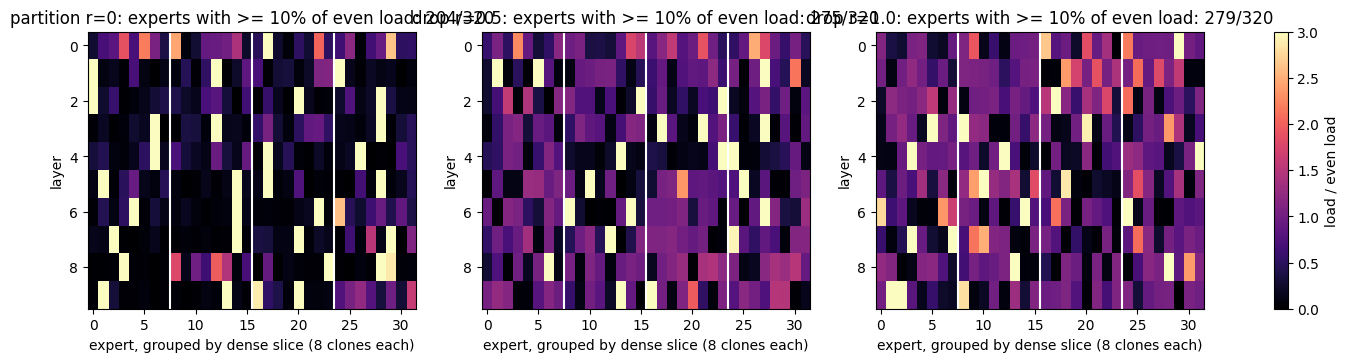

In [20]:
show = [n for n in ["partition r=0", "drop r=0.5", "drop r=1.0"] if n in SWEEP]
fig, axes = plt.subplots(1, len(show), figsize=(6 * len(show), 3.6))
for ax, name in zip(np.atleast_1d(axes), show):
    res = SWEEP[name]
    fam = res["family"]
    order = np.argsort(fam, kind="stable")                     # experts grouped by slice
    ld = res["loads"][-20:].mean(0)                            # (L, E)
    rel_load = ld / ld.mean(1, keepdims=True)                  # 1.0 = even load
    im = ax.imshow(rel_load[:, order], aspect="auto", cmap="magma", vmin=0, vmax=3)
    for b in range(1, int(fam.max()) + 1):
        ax.axvline(b * 8 - 0.5, color="white", lw=1.5)
    a, n = family_survivors(res)
    ax.set_title(f"{name}: experts with >= 10% of even load: {a}/{n}")
    ax.set_xlabel("expert, grouped by dense slice (8 clones each)"); ax.set_ylabel("layer")
plt.colorbar(im, ax=axes, label="load / even load")
savefig("sweep_clone_family_loads")

**Observations (§8).**

| variant | val at step 0 | val after 5M | vs dense control (1.9203) | clone similarity, start → end | MaxVio at end | experts with ≥ 10% of even load |
|---|--:|--:|--:|--:|--:|--:|
| copy 8 × 1,024, top-1 | 2.0040 | 1.9809 | +0.061 | 1.000 → 0.940 | 0.02 | 80 of 80 |
| partition r = 0 | 2.1930 | **1.9468** | **+0.027** | 1.000 → 0.944 | 6.69 | 204 of 320 |
| drop r = 0.25 | 2.3267 | 1.9701 | +0.050 | 0.563 → 0.538 | 6.30 | 231 of 320 |
| drop r = 0.5 | 2.7429 | 2.0002 | +0.080 | 0.250 → 0.244 | 5.18 | 275 of 320 |
| drop r = 1.0 | 7.5299 | 2.1103 | +0.190 | 0.000 → 0.000 | 3.32 | 279 of 320 |

* **No MoE caught the dense control in 5M tokens.** The final ranking follows how much dense knowledge each variant
  kept: partition r = 0 first, then r = 0.25, 0.5 and 1.0. As predicted, the smaller r stays ahead over a short
  budget. The drop-upcycling paper measured its advantage for r = 0.5 over far longer training, and it does not show
  here. In hindsight, partition r = 0 (or r = 0.25) would probably have suited the 20M-token main run better. That was
  not tested.
* **Copy started exactly at the dense loss but trained worse.** After 1.6M tokens it was 0.055 behind the dense
  control (2.0754 vs 2.0206), and it stayed about 0.06 behind. Partition, which started 0.19 behind, was only 0.03
  behind by then. A start without a jump buys nothing if training afterwards is slower. Two reasons follow from the
  code. First, with top-1 the renormalised weight is always exactly 1, so the language loss gives the router *no
  gradient at all*. Only the bias and the 1e-4 sequence loss move it, which is also why copy ends perfectly balanced
  (MaxVio 0.02). Second, each copy trains on about 1/8 of the batch, so its gradient is noisier than the dense
  model's, while Adam still takes full-size steps. The second reason is our most likely explanation; we did not test
  it separately.
* **Clone similarity starts at $(1-r)^2$**, as predicted (0.563, 0.250, 0). It hardly moves in 5M tokens: identical
  clones only fall to 0.94.
* **Collapse inside clone families, as the lesson describes.** With partition r = 0, only 204 of 320 experts still get
  at least 10% of the even load. The other 116 (36%) are nearly unused, close to the Lightning LM's 168 of 460 (37%).
  In the heatmap, each family has one or two bright clones and dark neighbours. Redrawing keeps more experts in use:
  231 at r = 0.25, 275 at r = 0.5 and 279 at r = 1.0. Even so, partition had the best loss, because at this budget
  the unused clones cost nothing measurable.
* MaxVio ends high for every 32-expert variant (3.3–6.7), although the bias is on. The largest possible value with
  top-4 of 32 is $32/4 - 1 = 7$. §9 shows why it stays high.
* Plot note: the three panel titles of the clone-family heatmap overlap. From left to right they are partition r = 0
  (204/320), drop r = 0.5 (275/320) and drop r = 1.0 (279/320).

## 9. Balancing: none, auxiliary loss, bias

The same drop r = 0.5 conversion, the same 5M tokens, three ways of keeping the load even:

| run | what it adds | coefficient |
|---|---|---|
| **no balancing** | nothing: the router picks the top-4 sigmoid scores | — |
| **auxiliary loss** (Switch Transformer) | $\alpha E \sum_i f_i P_i$ over the whole batch, added to the loss | $\alpha = 0.01$ |
| **bias + sequence aux** (main recipe, the r = 0.5 run of §8) | selection bias, $\gamma = 0.001$; plus $\alpha = 10^{-4}$ per sequence | |

**The feedback loop it fights (lesson §10).** An expert chosen slightly more often gets more gradient, gets better,
gets a higher score, and is chosen even more. The auxiliary loss pushes back through the router's *gradient*, so it
competes with the language loss. The bias pushes back *outside* the gradient. The lesson's numbers (Wang et al. 2024,
1B model): aux loss gave perplexity 9.56 with MaxVio 0.72, and the bias gave 9.50 with MaxVio 0.04.

**What the curves show.** MaxVio is computed from every training batch (131,072 assignments per layer) and averaged
over the 10 layers. "Dead experts" is the number of (layer, expert) pairs below 1% of the even load, out of 320.

**Predictions.**
* *no balancing*: MaxVio grows over the 152 steps, and some experts may die. The upcycled start already has a strong
  preference (§6), so the imbalance may be high from the first step.
* *aux 0.01*: MaxVio lower than with no balancing, but not near 0.
* *bias*: the bias moves at most $152 \times 0.001 = 0.15$ in this run. That is large next to the spread of the
  sigmoid scores at the start (std ≈ 0.025, §5), so MaxVio should fall within a few dozen steps and stay lowest.
* *Loss*: over only 5M tokens all three may be close. The lesson's gains from the bias method are small (0.06
  perplexity) and appear over long runs.

In [21]:
BAL = {}
for name, c in [("no balancing", replace(MOE, bias_gamma=0.0, aux_alpha=0.0, seq_aux_alpha=0.0)),
                ("aux loss 0.01", replace(MOE, bias_gamma=0.0, aux_alpha=0.01, seq_aux_alpha=0.0))]:
    m, _ = upcycle(dense, c, "partition", 0.5, seed=0)
    BAL[name] = train(m, train_tok, val_t, start_token=CONVERT_AT, n_tokens=SWEEP_TOKENS, batch=BATCH,
                      eval_every=25, log_every=50, label=f"balancing: {name}")
    del m; gc.collect(); torch.cuda.empty_cache()
BAL["bias 0.001 + seq-aux 1e-4"] = SWEEP["drop r=0.5"]
RESULTS["balancing"] = BAL; save_results()

print(f"\n{'balancing':28s} {'val end':>8s} {'MaxVio step 1':>14s} {'MaxVio last 20 steps':>21s} {'worst layer':>12s} "
      f"{'dead at end (of 320)':>21s}")
for name, res in BAL.items():
    mv = maxvio(res["loads"])                                  # (steps, L)
    ld = res["loads"][-20:].mean(0)
    print(f"{name:28s} {res['final_val']:8.4f} {mv[0].mean():14.2f} {mv[-20:].mean():21.2f} {mv[-20:].mean(0).max():12.2f} "
          f"{int(dead_experts(ld).sum()):21d}")

  [balancing: no balancing] 152 steps of 32,768 tokens, tokens 40M -> 45M;  val loss before the first step 2.7430
  [balancing: no balancing] step     1/152  tokens  40.01M  train loss 2.8584  grad norm 0.907  lr 5.00e-04  MaxVio (mean over layers) 1.55
  [balancing: no balancing] step    50/152  tokens  41.62M  train loss 2.3331  grad norm 0.244  lr 1.50e-03  MaxVio (mean over layers) 5.73   val 2.1416
  [balancing: no balancing] step   100/152  tokens  43.25M  train loss 1.8224  grad norm 0.271  lr 1.50e-03  MaxVio (mean over layers) 6.30   val 2.0881
  [balancing: no balancing] step   150/152  tokens  44.89M  train loss 2.1828  grad norm 0.243  lr 2.40e-04  MaxVio (mean over layers) 6.47   val 1.9931
  [balancing: no balancing] step   152/152  tokens  44.96M  train loss 1.6065  grad norm 0.212  lr 1.50e-04  MaxVio (mean over layers) 6.46
  [balancing: aux loss 0.01] 152 steps of 32,768 tokens, tokens 40M -> 45M;  val loss before the first step 2.7429
  [balancing: aux loss 0.01] ste

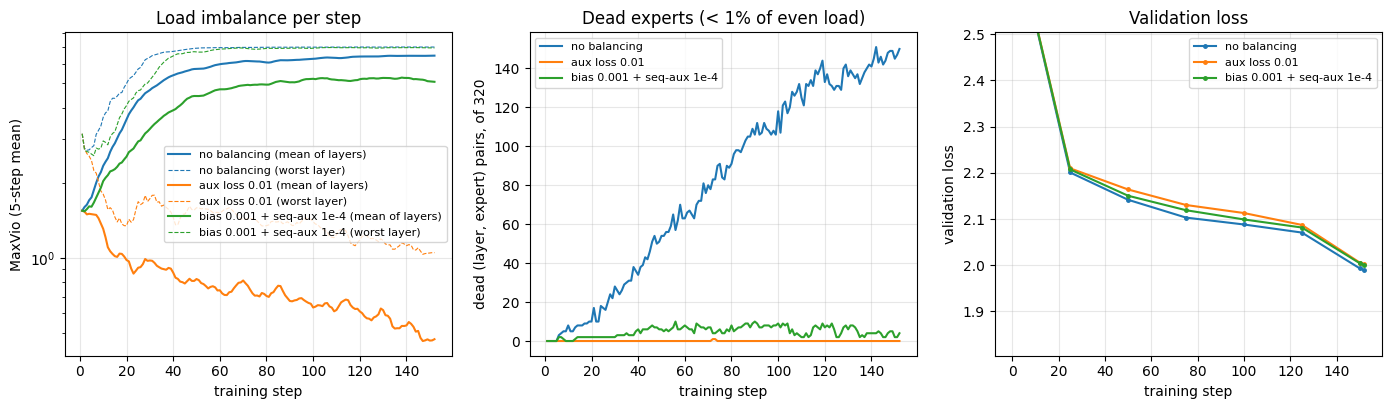

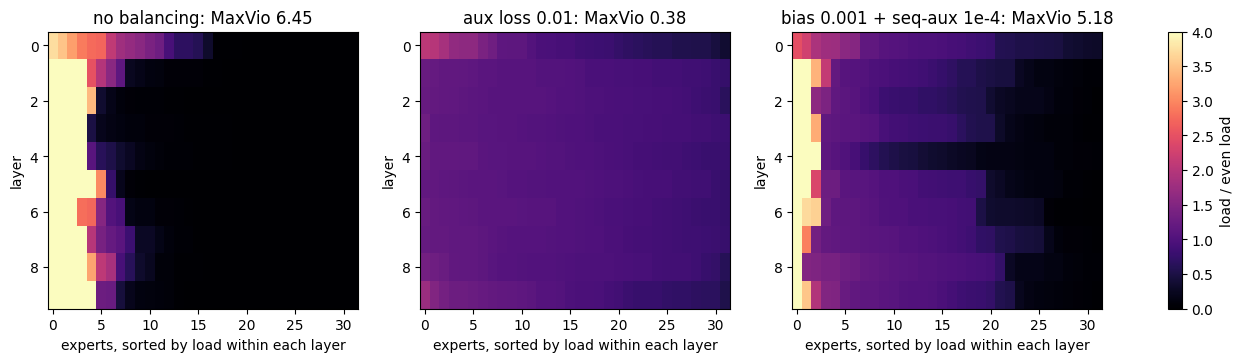

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for i, (name, res) in enumerate(BAL.items()):
    mv = maxvio(res["loads"])                                  # (steps, L)
    st = np.arange(1, len(mv) + 1)
    ax[0].plot(st, smooth(mv.mean(1), 5), color=f"C{i}", label=f"{name} (mean of layers)")
    ax[0].plot(st, smooth(mv.max(1), 5), color=f"C{i}", ls="--", lw=0.8, label=f"{name} (worst layer)")
    ax[1].plot(st, dead_experts(res["loads"]).sum(1), color=f"C{i}", label=name)
    vh = np.array(res["val_hist"])
    ax[2].plot(vh[:, 0], vh[:, 2], "o-", ms=2.5, color=f"C{i}", label=name)
ax[0].set(xlabel="training step", ylabel="MaxVio (5-step mean)", title="Load imbalance per step", yscale="log")
ax[1].set(xlabel="training step", ylabel="dead (layer, expert) pairs, of 320", title="Dead experts (< 1% of even load)")
ax[2].set(xlabel="training step", ylabel="validation loss", title="Validation loss")
ax[2].set_ylim(DENSE_VAL - 0.2, DENSE_VAL + 0.5)
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=8)
savefig("balancing_curves")

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, (name, res) in zip(axes, BAL.items()):
    ld = res["loads"][-20:].mean(0)
    rel_load = np.sort(ld / ld.mean(1, keepdims=True), axis=1)[:, ::-1]   # each layer sorted busiest first
    im = ax.imshow(rel_load, aspect="auto", cmap="magma", vmin=0, vmax=4)
    ax.set_title(f"{name}: MaxVio {maxvio(ld).mean():.2f}")
    ax.set_xlabel("experts, sorted by load within each layer"); ax.set_ylabel("layer")
plt.colorbar(im, ax=axes, label="load / even load")
savefig("balancing_load_heatmaps")

**Observations (§9).**

| balancing | val after 5M | MaxVio, last 20 steps | worst layer | dead experts at the end (of 320) |
|---|--:|--:|--:|--:|
| none | **1.9892** | 6.45 | 7.00 | **140** |
| aux loss α = 0.01 | 2.0016 | **0.50** | 1.08 | **0** |
| bias γ = 0.001 + sequence aux 1e-4 | 2.0002 | 5.19 | 6.95 | 3 |

* **Without balancing the routing collapses**, as predicted. MaxVio climbs from 1.55 to 6.45, and the worst layer
  reaches 7.00, the maximum possible, where one expert is chosen by every token. Dead experts rise almost linearly to
  **140 of 320** (44%). In the heatmap, most layers have 4–6 hot experts and the rest are dark.
* **The auxiliary loss balanced fastest.** MaxVio fell below 1 within about 20 steps and ended at 0.50, with no dead
  experts. That is better than predicted ("lower, but not near 0").
* **Prediction wrong: the bias did not balance in 152 steps.** MaxVio ended at 5.19, close to no balancing, because the
  bias is rate-limited. It moves by exactly 0.001 per step, so by at most 0.152 in this run. The router weights,
  however, are trained by Adam at the full learning rate, so the favoured experts' scores pulled away faster than the
  bias could follow. Given time, the bias catches up. In the main run (same conversion, 610 steps, §7), MaxVio peaked
  at about 4.3 near step 150 and fell to 0.42 by step 600. DeepSeek-V3 trains for hundreds of thousands of steps, so a
  few hundred steps of lag are negligible there. Our 152-step run is all lag.
* **The bias did stop experts from dying**: 3 dead experts instead of 140. Every step it raises the bias of every
  quiet expert, which keeps them above 1% of the even load even while a few experts stay hot. The heatmap shows 2–5
  bright experts per layer, about 20 near even load, and only a few dark ones.
* **Loss:** all three ended within 0.012 of each other, as predicted. No balancing is slightly best and the auxiliary
  loss slightly worst. That order fits the lesson's point that the auxiliary loss competes with the language loss, but
  0.012 is within single-seed noise. The cost of 140 dead experts (44% of the stored capacity unused) would only show
  over longer training.
* The heatmap titles give the MaxVio of the loads *averaged* over the last 20 steps (aux: 0.38). It is lower than the
  table's mean of the per-step values (0.50) because averaging smooths out per-step spikes.

## 10. What the experts learned (main MoE, after 20M tokens)

The lesson's §9 summarises measurement studies (ST-MoE, Mixtral, OLMoE): **experts mostly specialise by the kind of
token** (punctuation, function words, names, numbers), and much less by the subject of the text. Mixtral also found
that consecutive tokens share their top expert more often than chance: 24–28% in the middle layers against 12.5% by
chance with 8 experts.

**Method.** Route 128 validation windows (65,536 tokens) through the main MoE and record the 4 chosen experts of every
token in every layer. Each vocabulary entry is put into one rough category by its text: end of story, punctuation,
number, function word (*the, and, was, he, ...*), word piece (no leading space), capitalised word (mostly names and
sentence starts), *-ed* word, *-ing* word, other word. Then:

* **Concentration** of a category in a layer is the share of its assignments that go to its 4 most-used experts.
  Even routing gives $4/32 = 12.5\%$, and a category handled by one fixed group of 4 experts gives 100%.
* **Lift** of (category, expert) = (share of the category's assignments that go to the expert) / (share of all
  assignments that go to it). A lift of 1 means no preference; 4 means four times more than the average token.
* **Consecutive-token agreement**: how often a token's top-1 expert equals the previous token's, against the chance
  level $\sum_e p_e^2$ (with $p_e$ = share of top-1 choices of expert $e$).

**Prediction.** Punctuation, end-of-story and function words are the most concentrated (well above 12.5%). Ordinary
content words are the least. Agreement is above chance in most layers.

In [23]:
topi_m, ids_m, nxt_m = routing_probe(moe_main, val_t, 128)    # list over layers of (65536, 4), ids (65536,)
FUNC = set("the a an and to of was he she it they in on with his her said is i you we but so that for at had were "
           "there one day her him them their then this be not have do did can will would could my your".split())
NUMS = set("one two three four five six seven eight nine ten first second third hundred".split())
CATS = ["end of story", "punctuation", "number", "function word", "word piece (no space)", "capitalised word",
        "-ed word", "-ing word", "other word", "rare"]
EOT_NEW = int(lut[EOT])

def category(i):
    "Rough category of new token id i by its text. Example: category(lut[13]) -> 'punctuation'  ('.')"
    s = TOK_STR[i]; w = s.strip()
    if i == EOT_NEW: return "end of story"
    if i == RARE: return "rare"
    if w == "" or all(ch in string.punctuation for ch in w): return "punctuation"
    if w.isdigit() or w.lower() in NUMS: return "number"
    if w.lower() in FUNC: return "function word"
    if not s.startswith(" "): return "word piece (no space)"
    if w[0].isupper(): return "capitalised word"
    if w.endswith("ed"): return "-ed word"
    if w.endswith("ing"): return "-ing word"
    return "other word"

cat_of = torch.tensor([CATS.index(category(i)) for i in range(V)])
tok_cat = cat_of[ids_m]                                         # (N,) category of every routed token
N_tok, L_, E_, k_ = len(ids_m), MOE.n_layer, MOE.n_expert, MOE.top_k
n_per_cat = torch.bincount(tok_cat, minlength=len(CATS))
conc = np.zeros((len(CATS), L_)); lift = {}; agree = []
for l in range(L_):
    C = torch.zeros(len(CATS), E_)
    C.index_put_((tok_cat[:, None].expand(-1, k_).reshape(-1), topi_m[l].reshape(-1)), torch.ones(N_tok * k_),
                 accumulate=True)                               # (cats, E) assignment counts
    share = C / C.sum(1, keepdim=True).clamp_min(1)
    conc[:, l] = share.sort(1, descending=True).values[:, :4].sum(1).numpy()
    lift[l] = (share / (C.sum(0) / C.sum())).numpy()
    t1 = topi_m[l][:, 0].view(-1, SEQ)                          # (windows, T) top-1 expert
    p = torch.bincount(t1.flatten(), minlength=E_).float() / t1.numel()
    agree.append(((t1[:, 1:] == t1[:, :-1]).float().mean().item(), (p ** 2).sum().item()))

print(f"concentration: share of a category's assignments in its 4 most-used experts (even routing = 12.5%)\n")
print(f"{'category':24s} {'tokens':>7s} " + " ".join(f"{'L' + str(l):>6s}" for l in range(L_)))
for c, name in enumerate(CATS):
    if n_per_cat[c] >= 50:
        print(f"{name:24s} {n_per_cat[c].item():7d} " + " ".join(f"{100 * conc[c, l]:5.1f}%" for l in range(L_)))
print(f"\nconsecutive tokens with the same top-1 expert, measured vs chance (sum of p_e^2):")
print("  " + ",  ".join(f"L{l}: {a:.1%} vs {ch:.1%}" for l, (a, ch) in enumerate(agree)))
RESULTS["specialisation"] = dict(conc=conc, agree=agree, n_per_cat=n_per_cat.tolist(), cats=CATS); save_results()

concentration: share of a category's assignments in its 4 most-used experts (even routing = 12.5%)

category                  tokens     L0     L1     L2     L3     L4     L5     L6     L7     L8     L9
end of story                 304  77.5%  98.3%  95.8%  99.9%  90.3%  92.0%  77.3%  96.0%  88.0%  83.1%
punctuation                11542  46.8%  53.5%  55.9%  34.1%  32.2%  31.3%  39.3%  34.1%  36.4%  41.5%
number                       363  83.7%  64.9%  72.5%  63.1%  64.7%  65.2%  68.0%  65.2%  63.3%  59.3%
function word              23662  27.8%  23.0%  24.0%  23.0%  24.7%  20.5%  21.9%  20.3%  20.8%  23.2%
word piece (no space)       2927  30.9%  23.6%  30.9%  26.3%  26.0%  28.8%  25.4%  21.1%  27.1%  27.6%
capitalised word            2557  52.6%  40.4%  55.1%  48.5%  46.8%  37.7%  47.2%  35.3%  44.4%  43.0%
-ed word                    2685  34.1%  37.2%  35.7%  25.5%  30.1%  28.0%  37.4%  32.3%  25.0%  35.2%
-ing word                    759  39.9%  37.4%  35.5%  36.8%  28.9%  32.8%  

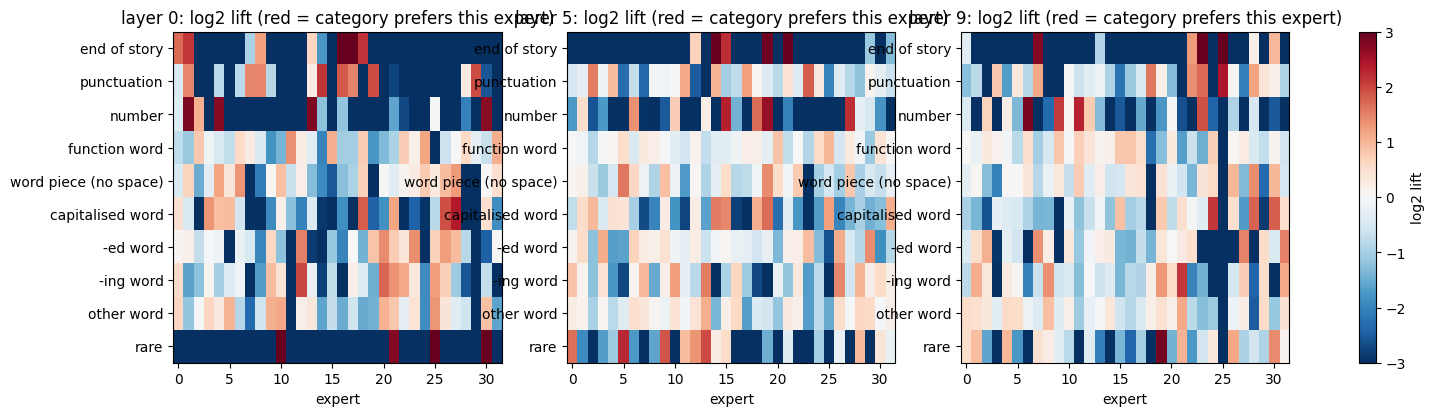

layer 5, expert 21 (highest lift: end of story, 8.1x): most frequent tokens, with the share of that token's occurrences routed here:
    '.' 19%, ',' 17%, ' was' 29%, '<|endoftext|>' 100%, ' time' 87%, '\n' 11%, ' named' 87%, ' a' 13%, ' "' 34%, ' to' 8%, ' girl' 92%, ' Lily' 17%
layer 5, expert 14 (highest lift: end of story, 8.0x): most frequent tokens, with the share of that token's occurrences routed here:
    '\n' 70%, '.' 11%, ',' 21%, ' and' 21%, ' Lily' 52%, '<|endoftext|>' 99%, ' said' 62%, ' She' 29%, ' He' 35%, ' They' 23%, '."' 47%, ' was' 10%
layer 5, expert 19 (highest lift: end of story, 7.5x): most frequent tokens, with the share of that token's occurrences routed here:
    ' a' 34%, ',' 20%, '\n' 20%, ' day' 76%, ' Lily' 54%, '<|endoftext|>' 100%, ' said' 61%, ' Tim' 62%, ' time' 83%, 'Once' 100%, ' saw' 90%, ' the' 10%
layer 5, expert 15 (highest lift: number, 5.0x): most frequent tokens, with the share of that token's occurrences routed here:
    ' and' 31%, ' mom' 9

In [24]:
layers = [0, L_ // 2, L_ - 1]
keep = [c for c in range(len(CATS)) if n_per_cat[c] >= 50]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for ax, l in zip(axes, layers):
    im = ax.imshow(np.log2(np.clip(lift[l][keep], 1 / 16, 16)), aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
    ax.set_yticks(range(len(keep))); ax.set_yticklabels([CATS[c] for c in keep])
    ax.set_xlabel("expert"); ax.set_title(f"layer {l}: log2 lift (red = category prefers this expert)")
plt.colorbar(im, ax=axes, label="log2 lift")
savefig("expert_specialisation_heatmaps")

# The most specialised experts of the middle layer, with the tokens they receive most
l = L_ // 2
occ = torch.bincount(ids_m, minlength=V).float()
best = np.argsort(-lift[l][keep].max(0))[:4]                   # the 4 experts with the highest category lift
for e in best:
    mask = (topi_m[l] == int(e)).any(1)                        # tokens that chose expert e
    routed = torch.bincount(ids_m[mask], minlength=V).float()
    top_ids = torch.argsort(-routed)[:12]
    c_best = keep[int(np.argmax(lift[l][keep][:, e]))]
    print(f"layer {l}, expert {int(e):2d} (highest lift: {CATS[c_best]}, {lift[l][c_best, e]:.1f}x): most frequent tokens, "
          f"with the share of that token's occurrences routed here:")
    print("    " + ", ".join(f"{TOK_STR[int(i)]!r} {routed[i] / occ[i]:.0%}" for i in top_ids))

**Observations (§10).** The routes come from the main MoE after 20M tokens. By then it is fairly balanced (MaxVio
0.4–0.7), so the specialisation is not an artefact of collapse.

* **The most concentrated categories are small ones with a clear role:** end of story (77–99.9% of its assignments
  in its 4 most-used experts), rare tokens (35–100%), numbers (59–84%), then punctuation (31–56%) and capitalised words
  (35–55%). Even routing gives 12.5%.
* **Prediction partly wrong: function words are the *least* concentrated** (20–28%), level with ordinary words
  (21–28%), not among the most. They are the largest category (23,662 of 65,536 tokens, 36%), and they are many
  different tokens with different jobs (*the, and, was, she, ...*). If 4 experts took all of them, each of those
  experts would get 2.9× the even load, and the bias would push back. A category that big has to spread.
* **Specialisation is sharper per token than per category.** In layer 5, ' time' sends 87% of its occurrences to
  expert 21 and ' girl' 92%. 'Once' (100%) and ' saw' (90%) go to expert 19, and ' mom' and ' One' (97% each) to
  expert 15. `<|endoftext|>` goes to experts 21, 14 and 19 almost every time (99–100%). Many tokens on these lists
  (*Once, time, One, day, named, girl*) typically open a TinyStories story ("Once upon a time…", "One day…", "a little
  girl named…"). So some experts may follow the position in the story as well as the token itself. We did not test
  this.
* **Consecutive tokens share their top-1 expert more often than chance, in every layer**, as predicted: 7.0–18.2%,
  against a chance level of 3.7–4.8%. The ratio grows with depth, from 1.5× in layer 0 to 3–5× from layer 4 on.
  Mixtral reports 24–28% against 12.5%, about 2×, with 8 experts.
* Plot note: the panel titles and y-axis labels of the lift heatmap overlap. The panels are layers 0, 5 and 9, and
  their rows are the categories of the table above, in the same order.

## 11. Capacity and token dropping (lesson §11)

Our MoE is **dropless**: an expert takes every token that chose it. Early MoEs gave each expert a fixed number of
slots,

$$\text{capacity} = \frac{\text{tokens} \times k}{E} \times \text{capacity factor (CF)},$$

and dropped the assignments that arrived after the expert was full. The token then gets nothing from that expert,
only the residual connection and its other experts. Here we take the trained main MoE and *evaluate* it with capacity
limits. The capacity is counted per forward batch of 64 × 512 tokens: $32{,}768 \times 4 / 32 = 4{,}096$ slots at
CF 1.0.

**Prediction.** The share of dropped assignments in a layer is $\sum_e \max(0, c_e - \text{cap}) / A$. It can be
computed from the dropless counts *before* running the capped model, and the measured value should match. With
MaxVio $m$, at least the busiest expert overflows at CF $< 1 + m$. The loss gets worse as CF shrinks. It is ≈ the
dropless loss at CF 2.0 if no expert exceeds twice the even load.

main MoE, first validation batch: MaxVio per layer [0.26, 0.43, 0.63, 0.44, 0.98, 0.42, 0.45, 1.16, 0.4, 0.96]
CF 0.50 (capacity 2,048 per expert) : validation loss (1,024 windows) 3.6990; dropped assignments measured 50.95% (predicted from the dropless counts of the first batch 50.45%)
CF 1.00 (capacity 4,096 per expert) : validation loss (1,024 windows) 1.8522; dropped assignments measured 7.11% (predicted from the dropless counts of the first batch 7.86%)
CF 1.25 (capacity 5,120 per expert) : validation loss (1,024 windows) 1.8177; dropped assignments measured 1.88% (predicted from the dropless counts of the first batch 1.82%)
CF 1.50 (capacity 6,144 per expert) : validation loss (1,024 windows) 1.8154; dropped assignments measured 0.94% (predicted from the dropless counts of the first batch 0.57%)
CF 2.00 (capacity 8,192 per expert) : validation loss (1,024 windows) 1.8140; dropped assignments measured 0.28% (predicted from the dropless counts of the first batch 0.05%)
dropless    

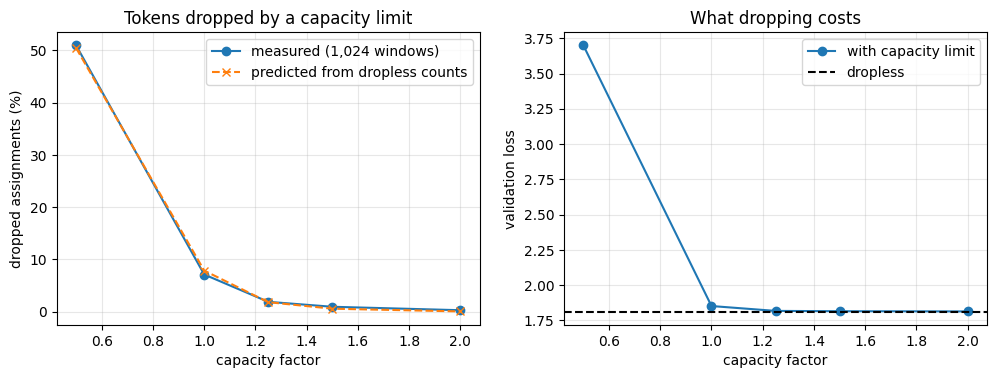

In [25]:
probe_topi, _, _ = routing_probe(moe_main, val_t, 64)          # exactly one capacity batch: 64 windows
A = probe_topi[0].numel()
cnt = np.stack([torch.bincount(t.flatten(), minlength=E_).numpy() for t in probe_topi])   # (L, E)
print(f"main MoE, first validation batch: MaxVio per layer {np.round(maxvio(cnt), 2).tolist()}")
CAP = {}
for cf in [0.5, 1.0, 1.25, 1.5, 2.0, 0.0]:
    if cf > 0:
        cap_ = math.ceil(A / E_ * cf)
        pred = float(np.mean(np.maximum(cnt - cap_, 0).sum(1) / A))
    else:
        cap_, pred = None, 0.0
    loss, drop = evaluate_capacity(moe_main, val_t, cf)
    CAP[cf] = dict(loss=loss, drop=drop, pred=pred)
    lab = f"CF {cf:4.2f} (capacity {cap_:,} per expert)" if cf > 0 else "dropless"
    print(f"{lab:36s}: validation loss (1,024 windows) {loss:.4f}; dropped assignments measured {drop:.2%} "
          f"(predicted from the dropless counts of the first batch {pred:.2%})")
RESULTS["capacity"] = CAP; save_results()

cfs = [c for c in CAP if c > 0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(cfs, [100 * CAP[c]["drop"] for c in cfs], "o-", label="measured (1,024 windows)")
ax[0].plot(cfs, [100 * CAP[c]["pred"] for c in cfs], "x--", label="predicted from dropless counts")
ax[0].set(xlabel="capacity factor", ylabel="dropped assignments (%)", title="Tokens dropped by a capacity limit")
ax[1].plot(cfs, [CAP[c]["loss"] for c in cfs], "o-", label="with capacity limit")
ax[1].axhline(CAP[0.0]["loss"], color="k", ls="--", label="dropless")
ax[1].set(xlabel="capacity factor", ylabel="validation loss", title="What dropping costs")
for a in ax:
    a.grid(alpha=0.3); a.legend()
savefig("capacity_dropping")

**Observations (§11).**

| capacity factor | slots per expert | dropped, measured | dropped, predicted | val loss | vs dropless |
|---|--:|--:|--:|--:|--:|
| 0.5 | 2,048 | 50.95% | 50.45% | 3.6990 | +1.886 |
| 1.0 | 4,096 | 7.11% | 7.86% | 1.8522 | +0.039 |
| 1.25 | 5,120 | 1.88% | 1.82% | 1.8177 | +0.005 |
| 1.5 | 6,144 | 0.94% | 0.57% | 1.8154 | +0.002 |
| 2.0 | 8,192 | 0.28% | 0.05% | 1.8140 | +0.001 |
| dropless | – | 0 | 0 | **1.8130** | – |

* **The drop rate can be predicted from the dropless counts.** The first batch alone gives every value to within 0.8
  percentage points. The small gaps come from the other 15 batches having different loads.
* **The more is dropped, the more loss it costs.** At CF 1.0, 7% of the assignments are dropped and the loss rises by
  0.039, which is more than the MoE's whole gap to the dense model (0.022). CF 1.25 costs 0.005 and CF 2.0 costs 0.001.
  CF 0.5 throws away half of the experts' work, and the model breaks (3.70).
* Even CF 2.0 drops 0.28%. In the first batch, layer 7 had MaxVio 1.16, so its busiest expert held more than twice
  the even load. This is the "CF < 1 + MaxVio" rule from the prediction.
* This is the lesson's argument for dropless dispatch (§11): it loses no quality. Its only price is that the experts
  get unequal amounts of work.

## 12. Cost: parameters, compute, speed, memory

The lesson's §6 says **compute follows the active parameters, and memory follows the total**. Our two phase-B runs
check this:

* **Compute.** Both models do about $6 \times 21\text{M} \approx 126$ MFLOP per token (forward + backward, matrix
  products only, attention scores excluded). The MoE adds only the router ($2 \times 384 \times 32$ per layer, under
  1%).
* **Memory for weights + Adam** grows with the total: 16 bytes per parameter in mixed-precision training
  (fp32 weight 4 + gradient 4 + Adam $m$ 4 + $v$ 4) gives $20.8\text{M} \times 16 = 0.33$ GB for dense and
  $103.5\text{M} \times 16 = 1.66$ GB for the MoE. Activations are similar, because a token uses the same width.
* **Speed** is not set by FLOPs alone. Our MoE runs 32 small matrix-product chains per layer in a Python loop, reads
  the expert counts back to the CPU once per layer (a synchronisation), and gathers and scatters the token rows.
  Production code uses grouped GEMM kernels (MegaBlocks, `torch._grouped_mm`) to avoid most of this.

In [26]:
dc, mm = RESULTS["dense_continued"], RESULTS["moe_main"]
pc_d, pc_m = count_params(dense), count_params(moe_main)
print(f"{'':28s} {'dense':>14s} {'upcycled MoE':>14s} {'MoE / dense':>12s}")
for lab, a, b in [("total parameters", pc_d["total"], pc_m["total"]), ("active parameters", pc_d["active"], pc_m["active"]),
                  ("FLOP per token (6 x active)", 6 * pc_d["active"], 6 * pc_m["active"]),
                  ("weights + Adam, 16 B/param", 16 * pc_d["total"], 16 * pc_m["total"])]:
    print(f"{lab:28s} {a:14,} {b:14,} {b / a:12.2f}")
print(f"{'measured tokens / s':28s} {dc['tok_per_s']:14,.0f} {mm['tok_per_s']:14,.0f} {mm['tok_per_s'] / dc['tok_per_s']:12.2f}")
print(f"{'measured peak memory (GiB)':28s} {dc['peak_gib']:14.2f} {mm['peak_gib']:14.2f} {mm['peak_gib'] / dc['peak_gib']:12.2f}")
print(f"{'phase-B wall time (min)':28s} {dc['wall_s'] / 60:14.1f} {mm['wall_s'] / 60:14.1f} {mm['wall_s'] / dc['wall_s']:12.2f}")
print(f"\nquality per unit of training compute: at the same tokens and FLOP per token, the MoE's final validation loss "
      f"differs from the dense model's by {mm['final_val'] - dc['final_val']:+.4f}")

                                      dense   upcycled MoE  MoE / dense
total parameters                 20,848,512    103,546,752         4.97
active parameters                20,848,512     20,971,392         1.01
FLOP per token (6 x active)     125,091,072    125,828,352         1.01
weights + Adam, 16 B/param      333,576,192  1,656,748,032         4.97
measured tokens / s                  75,869         18,460         0.24
measured peak memory (GiB)            10.52          17.31         1.64
phase-B wall time (min)                 4.8           18.9         3.91

quality per unit of training compute: at the same tokens and FLOP per token, the MoE's final validation loss differs from the dense model's by +0.0219


**Observations (§12).**

* **Compute follows the active parameters, and weight memory follows the total**, as the lesson's §6 says. Active
  parameters and FLOP per token are 1.01× the dense model's. Total parameters and the memory for weights + Adam are
  4.97× (1.66 GB against 0.33 GB).
* **Prediction wrong: the speed is 0.24× the dense model's, not 0.6–0.8×.** At equal FLOPs the MoE took 4× as long.
  Each MoE layer runs 32 experts × 3 matrix products in a Python loop on blocks of about 4,000 rows, twice that in the
  backward pass, and it reads the expert counts back to the CPU once per layer. It also gathers 131,072 token rows and
  scatter-adds them back. At this size, these small kernels and copies cost more than the arithmetic. Grouped-GEMM
  kernels exist to remove exactly this overhead.
* **Peak memory is 1.64×** (17.31 against 10.52 GiB), and weights, gradients and Adam explain only 1.2 GiB of the
  6.8 GiB difference. **The assumption above that activations are about the same size was wrong.** The hidden width
  per token is the same (4 × 256 = 1,024), but every token is copied 4 times into the expert buffers. So the 384-wide
  tensors kept for the backward pass (the gathered inputs, and the expert outputs in fp32) are 4× the dense FFN's. By
  our rough count that adds about 2.6 GiB over 10 layers, so roughly 4 of the 6.8 GiB are explained. We did not
  profile the rest.
* **Wall time** for phase B was 18.9 minutes against 4.8. At equal wall-clock time with this code, the dense model
  would win easily. The lesson compares at equal FLOPs, and there the from-scratch MoE won (§7).

## 13. Summary

| task | what was done | measured |
|---|---|---|
| **1. Train a dense model** | 20.8M-parameter Llama-style decoder, first 40M TinyStories tokens, warm-up + constant LR | val **2.0041**, still falling (−0.10 over the last 7M tokens); 76k tokens/s, 9.2 min |
| **2. Convert it into an MoE** | each FFN → 32 experts of width 256, top-4, sigmoid router, routed scale 4, drop-upcycling r = 0.5; 103.5M total / 21.0M active parameters | val **2.7429** right after the conversion (+0.739). Copy + top-1 reproduces the dense loss exactly (2.0040) |
| **3. Keep training, loss must fall** | 20M new tokens, fresh AdamW, WSD schedule | **13 of 13** evaluations lower than the one before; 2.7429 → **1.8130**; below the conversion-point dense loss after 11.5M tokens |

**Answers.**

* **Did the MoE keep training and reduce its loss?** Yes. It fell by 0.930 in 20M tokens and ended 0.191 below the
  dense model it came from.
* **Did it beat the dense control at equal compute?** Not within 20M tokens: it ended 0.022 behind dense continued
  (1.7911), with the gap shrinking from 0.142. The same MoE trained from scratch on all 60M tokens beat both (1.6963).
  So the MoE design works at this scale, and what held the upcycled model back was the jump at the conversion.
* **Which conversion?** Over 5M tokens, the variant that keeps the most dense knowledge wins: partition r = 0 (+0.027
  against dense), then r = 0.25, 0.5 and 1.0. Copy matched the dense loss at step 0 but trained worse (+0.061).
  Partition loses 36% of its experts to collapse inside clone families, and redrawing r = 0.5 cuts that to 14%.
* **Which balancing?** Over 152 steps only the auxiliary loss balanced the load (MaxVio 0.50). The bias needed about
  450 steps, as the main run shows, but it kept experts from dying from the start (3 dead, against 140 without
  balancing). The losses differed by at most 0.012.
* **What did the experts learn?** They specialise by single token far more than by category. End-of-story tokens,
  numbers and punctuation are concentrated in a few experts. Single tokens like ' girl', ' mom' and 'Once' go to one
  expert 90–100% of the time. Consecutive tokens share their top expert 1.5–5× more often than chance.
* **What does dropping cost?** CF 1.0 drops 7% of the assignments and costs 0.039, more than the MoE's whole gap to
  the dense model. CF 1.25 costs 0.005. Dropless is best.

**Predictions that turned out wrong.** They are kept in the text above as they were written before the run.

| § | prediction | measured |
|---|---|---|
| 5 | a freshly initialised router spreads the load evenly (MaxVio well below 1) | MaxVio 3.06; one expert gets 4.1× the even load |
| 7 | the upcycled MoE ends below dense continued | 0.022 above it |
| 7 | it gets back below the conversion-point loss within a few million tokens | after 11.5M tokens |
| 7 | the MoE from scratch ends above the upcycled MoE | 0.117 below it, the best model of all |
| 7 | MoE speed 0.6–0.8× the dense model's | 0.24× |
| 9 | the bias balances fastest and ends with the lowest MaxVio | the auxiliary loss balanced within ~20 steps; the bias needs ~450 |
| 10 | function words are among the most concentrated categories | they are the least concentrated |
| 12 | activations are about the same size as the dense model's | peak memory 1.64×; every token is copied 4× into the expert buffers |

## Limits of this work

* **One seed per run.** Differences of a few thousandths in validation loss are within run-to-run noise. Assignment 13
  found the bf16 noise floor alone at about 0.4% of the gradient.
* **Short budgets.** 40M + 20M tokens for the main runs and 5M for the sweeps. The lesson's comparisons (upcycling vs
  scratch, aux vs bias, r = 0.5) were measured over hundreds of billions of tokens and may rank differently at our
  scale.
* **r = 0.5 for the main run was fixed before the sweep.** The sweep then favoured r = 0 at 5M tokens, so a 20M-token
  run with r = 0 or 0.25 might have reached the dense control. It was not run.
* **The balancing comparison is short.** With γ = 0.001 the bias needs a few hundred steps to catch up with a fresh
  router, so a 152-step comparison favours the auxiliary loss. A larger γ or a longer comparison was not tried.
* **Small model.** 10 layers, 32 experts. At this size the routing statistics (§10) are rough, and the token
  categories are a hand-made heuristic based on the token text.
* **Fixed choices, not tuned.** The learning rate came from Assignment 13. The router init, γ, the auxiliary
  coefficients and the routed scaling factor of 4 follow the lesson and were not swept.
* **Single GPU, no expert parallelism.** Lesson §16–17 (all-to-all, EP layouts) appears only as arithmetic (§1.10).
  Our speed numbers come from a naive per-expert loop, not a grouped-GEMM kernel, so they understate what an MoE can
  reach. That slowness (4× the dense model's wall time) is also what limited the token budgets.
* **Fresh optimizer at the conversion** for every phase-B run, including the dense control. Carrying over Adam's
  moments for the copied weights was not tried.

## Release the Colab runtime

The last cell disconnects the runtime so it stops using compute units. **After it runs, press Ctrl+S in VS Code**, so
the notebook is saved with all its outputs. The README and the plots are extracted from them.

In [27]:
save_results()
try:
    from google.colab import runtime
    print("All done. Releasing the Colab runtime now; press Ctrl+S in VS Code to keep the outputs.")
    runtime.unassign()
except Exception as e:
    print(f"Not on Colab, or the runtime could not be released automatically ({e}); disconnect it manually.")

All done. Releasing the Colab runtime now; press Ctrl+S in VS Code to keep the outputs.
